In [1]:
import numpy as np
from matplotlib import pyplot as plt
from IPython import display

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

import cv2
import tempfile, os, re

import requests
import json
import time
import random
import unicodedata
import pandas as pd
import base64
import mimetypes


In [2]:
#functions from the feature extraction pipeline
def normalize_text(text):
    # Normalize unicode characters, remove markdown formatting, lowercase, and strip dashes
    if not text:
        return text
    
    text = str(text)
    text = text.replace('*', '').replace('<<', '').replace('>>', '')
    text = re.sub(r'[-\u2010-\u2015\u2212\uFE58\uFE63\uFF0D]', '', text)
    normalized = unicodedata.normalize('NFKD', text)
    ascii_text = normalized.encode('ASCII', 'ignore').decode('ASCII')

    # Clean up whitespace + lowercase
    return ' '.join(ascii_text.split()).lower()

def send_prompt(
    system=None,
    prompt=None,
    image_url=None,             # if set, we download to a temp file and inline it
    image_path=None,            # local file path (sent as data URL)
    image_detail="auto",        
    seed=None,
    azure_api_key=os.getenv("AZURE_API_KEY"),
    azure_chat_url=None,        # built if not provided
    azure_model_name=os.getenv("AZURE_MODEL_NAME"),
    max_completion_tokens=1024,
    temperature=float(os.getenv("TEMPERATURE", "1.0")),
    top_p=float(os.getenv("TOP_P", "1.0")),
    frequency_penalty=float(os.getenv("FREQUENCY_PENALTY", "0.0")),
    presence_penalty=float(os.getenv("PRESENCE_PENALTY", "0.0")),
    max_time=int(os.getenv("MAX_TIME", "30"))
):

    # --- default azure_chat_url if not supplied ---
    if azure_chat_url is None:
        azure_endpoint_base = "https://aipolling.services.ai.azure.com/models"
        azure_api_version  = "2024-05-01-preview"
        azure_chat_url = f"{azure_endpoint_base}/chat/completions?api-version={azure_api_version}"

    # --- helpers ---
    def guess_mime_from_ext(path):
        """Guess MIME type from file extension, fallback to image/jpeg."""
        mime, _ = mimetypes.guess_type(path)
        return mime if mime else "image/jpeg"

    def image_to_data_url(path, mime=None):
        """Read file, encode as base64, return as data URL."""
        if not os.path.exists(path):
            raise FileNotFoundError(f"image_path not found: {path}")
        if mime is None:
            mime = guess_mime_from_ext(path)
        with open(path, "rb") as f:
            encoded = base64.b64encode(f.read()).decode("utf-8")
        return f"data:{mime};base64,{encoded}"

    tmp_path = None
    # If image_url is provided, download it
    if image_url:
        ext = os.path.splitext(image_url)[1].lower()
        suffix = ext if ext else ".bin"
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=suffix)
        os.close(tmp_fd)  # we'll reopen with write
        resp_img = requests.get(image_url, timeout=max_time)
        if resp_img.status_code >= 400:
            raise RuntimeError(f"Failed to download image_url (HTTP {resp_img.status_code}): {image_url}")
        with open(tmp_path, "wb") as f:
            f.write(resp_img.content)
        image_path = tmp_path

    # --- build messages ---
    messages_list = []
    if system:
        messages_list.append({"role": "system", "content": system})

    user_content = [{"type": "text", "text": prompt}]

    if image_path:
        mime = guess_mime_from_ext(image_path)
        data_url = image_to_data_url(image_path, mime)
        user_content.append({
            "type": "image_url",
            "image_url": {"url": data_url, "detail": image_detail}
        })

    messages_list.append({"role": "user", "content": user_content})

    # --- body payload ---
    body = {
        "model": azure_model_name,
        "messages": messages_list,
        "temperature": float(temperature),
        "top_p": float(top_p),
        "frequency_penalty": float(frequency_penalty),
        "presence_penalty": float(presence_penalty),
        "max_completion_tokens": int(max_completion_tokens),
        "max_tokens": int(max_completion_tokens),  # compat
        "seed": int(seed) if seed is not None else None
    }

    # --- request ---
    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json",
        "api-key": azure_api_key
    }

    resp = requests.post(
        azure_chat_url,
        headers=headers,
        json=body,
        timeout=max_time
    )

    raw_content = resp.text
    if resp.status_code != 200:
        raise RuntimeError(f"API request failed with status {resp.status_code}, body: {raw_content}")

    result = resp.json()

    # --- cleanup tmp file if used ---
    if tmp_path and os.path.exists(tmp_path):
        try:
            os.remove(tmp_path)
        except Exception:
            pass

    return result

# ------------------------------------------------------------
# 2. Load demographic categories from JSON
# ------------------------------------------------------------
with open("../generated_data/image_belief_features.json", "r", encoding="utf-8") as f:
    feature_data = json.load(f)

demo_features = feature_data["demo"]

# Normalize titles for the matching
for demo in demo_features:
    demo["title"] = normalize_text(demo["title"])

# ------------------------------------------------------------
# 3. Image prompt for demographic features
# ------------------------------------------------------------
image_prompt_template = """
I will show you a social media user's profile image.

Based SOLELY on this profile image, I will show you a number of demographic categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
Please select, for each title, the most likely category to which this user belongs to BASED SOLELY ON THE VISUAL CONTENT OF THE PROFILE IMAGE.

In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.

For each selected symbol / category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, clear visual evidence in the profile image) to 100 (fully speculative, no visual information related to this title in the profile image).
Speculation levels should be a direct measure of the amount of useful visual information available in the profile image.
Speculation levels pertain only to the visual information available in the profile image and should not be affected by additional information available to you from any other source.


To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The profile image provides clear and direct visual information relevant to the title (e.g., explicit visual evidence of age, gender presentation, etc.)
21-40 (Moderate-low speculation): The profile image provides indirect but strong visual indicators relevant to the title.
41-60 (Moderate speculation): The profile image provides some visual hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The profile image provides limited and weak visual indicators relevant to the title.
81-100 (High speculation): The profile image provides no or almost no visual information relevant to the title.

For each selected category, please explain at length what visual features of the profile image contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

title: AGE
explanation: ...
symbol: A1)
category: 18-25
speculation: 90

For every title, you must include exactly these 5 fields: title, explanation, symbol, category, speculation. Do not omit any of them.
Please keep the EXACT WORDING for the titles!
YOU MUST GIVE AN ANSWER FOR EVERY TITLE!
"""

# ------------------------------------------------------------
# 4. Build dynamic image demographic prompt
# ------------------------------------------------------------
def build_image_demo_prompt(demo_features):
    
    # randomly shuffle the demographics to prevent position bias
    shuffled_demo = demo_features[:]
    random.shuffle(shuffled_demo)

    categories_text = "\n".join(
        [
            f"- **{demo['title']}:** \n    Choose one: [\n    " +
            ", \n    ".join([f"{key}) {val}" for key, val in demo["options"].items()]) +
            "]"
            for demo in shuffled_demo
        ]
    )

    return image_prompt_template + "\n\nBelow is the list of demographic categories to which this user may belong to:\n" + categories_text

# ----------------------------
# 5. Result Parsing Function
# ----------------------------

def parse_demo_response(response, demo_features, prefix="Image_Demo"):
    categories = {}
    explanations = {}
    speculations = {}
    symbols = {}

    for demo in demo_features:
        safe_key = re.sub(r"\W+", "_", demo["title"])
        if prefix:
            safe_key = f"{prefix}_{safe_key}"
        categories[f"{safe_key}_Category"] = None
        explanations[f"{safe_key}_Explanation"] = None
        symbols[f"{safe_key}_Symbol"] = None
        speculations[f"{safe_key}_Speculation"] = None

    demo_sections = re.split(r"(?=title:\s*)", str(response), flags=re.IGNORECASE)
    demo_sections = [section.strip() for section in demo_sections if section.strip() and not section.lower().startswith('below')]
    print(f"[DEBUG] Found {len(demo_sections)} sections to parse") 
    
    # Pattern for individual demographic
    pattern = (
        r"title:?\s*(.*?)\s*[\r\n]"
        r"explanation:?\s*(.*?)\s*[\r\n]"
        r"symbol:?\s*(.*?)\s*[\r\n]"
        r"category:?\s*(.*?)\s*[\r\n]"
        r"speculation:?\s*(\d+)\s*"
    )
    
    for i, section in enumerate(demo_sections):
        
        match = re.search(pattern, section, re.DOTALL | re.IGNORECASE)
        
        if match:
            title = normalize_text(match.group(1))
            explanation = normalize_text(match.group(2))
            symbol = normalize_text(match.group(3))
            category = normalize_text(match.group(4))
            speculation = normalize_text(match.group(5))
            
            matched_demo = None
            for d in demo_features:
                if d["title"] in title or title in d["title"]:
                    matched_demo = d
                    break
            if matched_demo:
                safe_key = re.sub(r"\W+", "_", matched_demo["title"])
                if prefix:
                    safe_key = f"{prefix}_{safe_key}"
                categories[f"{safe_key}_Category"] = category.strip()
                explanations[f"{safe_key}_Explanation"] = explanation.strip()
                symbols[f"{safe_key}_Symbol"] = symbol.strip()
                speculations[f"{safe_key}_Speculation"] = int(speculation.strip())

    return {**categories, **explanations, **speculations, **symbols}

# ------------------------------------------------------------
# 6. Build the request body for image inference using send_prompt
# ------------------------------------------------------------
def infer_image_demographics(image_url = None, image_path = None, model_name = None, demo_features = None):
    prompt = build_image_demo_prompt(demo_features)
    
    system_message = "You are a helpful assistant."

    try:
        result = send_prompt(
            system=system_message,
            prompt=prompt,
            image_url=image_url,
            image_path = image_path,
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 7. Secondary GPT cleanup function
# ------------------------------------------------------------
image_cleanup_prompt_template = """
You will be shown a long-form response to a question asking to assign a series of demographic categories to a user based solely on their profile image.
Your task is to extract and reformat the category assessments into a strict format.

CRITICAL FORMATTING RULES:
- Each demographic must be formatted EXACTLY as follows:
title: <FULL TITLE TEXT>
explanation: <FULL EXPLANATION TEXT>
symbol: <SYMBOL CODE>
category: <FULL CATEGORY TEXT>
speculation: <NUMERIC VALUE ONLY>

- Each field must be on its own separate line
- Preserve ALL original content from explanations, categories, and titles - do not summarize or shorten
- For speculation, use ONLY the numeric value (e.g., "50" not "fifty" or "50%")
- Remove any asterisks, markdown, or extra formatting from the original
- Ensure there is exactly one blank line between each complete demographic assessment
- If any field is missing, include the field name with nothing after it (e.g., "explanation:")

CHARACTER AND ENCODING RULES:
- Use only standard ASCII hyphens (-) for all dashes and hyphens in titles and categories
- Replace any special dashes (‑, –, —) with regular hyphens (-)
- Ensure all text uses standard ASCII characters only
- Remove any non-ASCII characters or convert them to their closest ASCII equivalent
- Use regular parentheses () not special parentheses

EXAMPLES OF CORRECT FORMATTING:

Example 1:
title: AGE
explanation: The profile image shows a person with visible wrinkles and gray hair...
symbol: A1)
category: 18-25
speculation: 50

Example 2:
title: SEX
explanation: The profile image presents masculine facial features and short haircut...
symbol: E1)
category: Male
speculation: 75

COMMON MISTAKES TO AVOID:
- WRONG: speculation: fifty (50)
- CORRECT: speculation: 50

- WRONG: symbol: E1) (with extra spaces)
- CORRECT: symbol: E1)

- WRONG: Using markdown like **title:**
- CORRECT: title:

- WRONG: Combining multiple fields on one line
- CORRECT: Each field on its own line

Now, clean and reformat the following response to match this exact structure. Preserve all original meaning but enforce the strict formatting and character rules:

{raw_output}
"""

def clean_image_output(raw_output, model_name):
    system_message = "You are a helpful assistant."
    
    try:
        result = send_prompt(
            system=system_message,
            prompt=image_cleanup_prompt_template.format(raw_output=raw_output),
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in cleanup send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 8. GPT call with retry logic for image demographics
# ------------------------------------------------------------
def infer_image_demographics_with_retry(image_source, model_name, demo_features, prefix="Image_Demo", max_retries=5):
    parsed_result = {}
    response_text = None
    cleaned_text = None
    
    for attempt in range(1, max_retries + 1):
        try:
            if str(image_source).startswith("http"):
                response_text = infer_image_demographics(
                    image_url = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
            else:
                response_text = infer_image_demographics(
                    image_path = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
                
            parsed_result = parse_demo_response(response_text, demo_features, prefix=prefix)

            # if parsed result is incomplete, proceed with secondary cleanup
            if any(value is None for value in parsed_result.values()):
                print(f"[DEBUG] Parsing incomplete for image demographics → attempting cleanup.")
                cleaned_text = clean_image_output(response_text, model_name)
                parsed_result = parse_demo_response(cleaned_text, demo_features, prefix=prefix)

            # if still incomplete, raise exception to retry full GPT
            if any(value is None for value in parsed_result.values()):
                raise ValueError("Parsed result is empty. Retrying...")
            else:
                print(f"Image demographic parsing succeeded")
            return response_text, cleaned_text, parsed_result

        except Exception as e:
            print(f"Attempt {attempt}/{max_retries} failed for image demographics ({model_name}): {e}")
            if attempt < max_retries:
                time.sleep(2 ** attempt * 0.1)  
    
    return response_text, cleaned_text, parsed_result

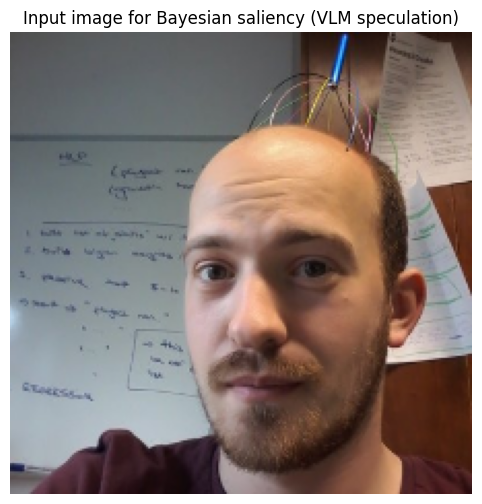

In [3]:
#load input
def load_image_from_url_or_path(image_source, input_size=None):
    if str(image_source).startswith("http"):
        resp = requests.get(image_source, timeout=30)
        img = cv2.imdecode(np.frombuffer(resp.content, np.uint8), cv2.IMREAD_COLOR)
    else:
        img = cv2.imread(image_source)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if input_size is not None:
        img = cv2.resize(img, input_size)
    return img

image_path = "https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg"
img = load_image_from_url_or_path(image_path, input_size=(224, 224))
h, w = img.shape[:2]

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.title("Input image for Bayesian saliency (VLM speculation)")
plt.show()


In [4]:
# Create sampling grid (position, and blanking window size)
x,y,w,h = np.meshgrid(np.linspace(0,32,32),np.linspace(0,32,32),np.linspace(1,8,7),np.linspace(1,8,7))

X = np.vstack((x.ravel(),y.ravel(),w.ravel(),h.ravel())).T

# Storage for samples
Xm = []
fm_dict = {}

# First sample
state = X[np.random.randint(0,X.shape[0]),:].astype(int)
Xm.append(state)


In [5]:
_, _, base_result = infer_image_demographics_with_retry(
    image_source=image_path,
    model_name= "Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    prefix="Image_Demo",
)

# Build a dict of baseline speculation scores for all demographics
baseline_scores = {}
for demo in demo_features:
    key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
    baseline_scores[key] = base_result.get(key, np.nan)

# Initialize per-feature sample arrays
for key in baseline_scores.keys():
    fm_dict[key] = []

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


In [6]:
h, w = img.shape[:2]
h, w = int(h), int(w)


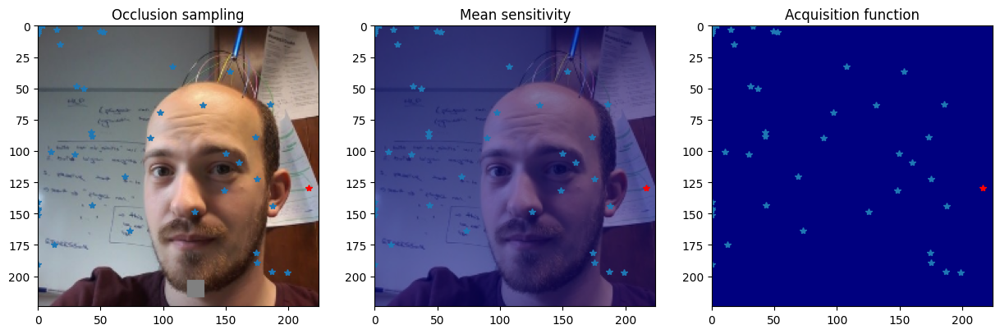

2025-10-12 12:21:17 | PID 576816 | RSS   355.4 MB | Plot updated
2025-10-12 12:21:17 | PID 576816 | RSS   355.4 MB | ITER 1 start | len(Xm)=49 | len(fm_dict)=6
2025-10-12 12:21:17 | PID 576816 | RSS   355.4 MB | Occlusion applied: grid=(29.00,16.00,4.00,2.00) → px=(175,98,224,126) img_size=(224,224) | patch=(49x28)
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
2025-10-12 12:21:22 | PID 576816 | RSS   355.4 MB | VLM call OK in 5.03s; keys=['Image_Demo_ethnicity_Category', 'Image_Demo_age_Category', 'Image_Demo_sex_Category', 'Image_Demo_highest_educational_qualification_Category', 'Image_Demo_household_income_bracket_Category']
2025-10-12 12:21:22 | PID 576816 | RSS   355.4 MB | Deltas computed
2025-10-12 12:21:22 | PID 576816 | RSS   355.4 MB | fm_mean built with shape (49,)
2025-10-12 12:21:22 | PID 576816 | RSS   355.4 MB | GP fitted
2025-10-12 12:21:22 | PID 576816 | RSS   355.9 MB | GP predict OK | mu.range=(0.0000,0.0000) | sig.range=(1.0000,1.0000)
2025-10

/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


2025-10-12 12:21:23 | PID 576816 | RSS   355.9 MB | ITER 2 start | len(Xm)=50 | len(fm_dict)=6
2025-10-12 12:21:23 | PID 576816 | RSS   355.9 MB | Occlusion applied: grid=(23.00,0.00,8.00,4.00) → px=(105,0,217,28) img_size=(224,224) | patch=(112x28)


KeyboardInterrupt: 

In [22]:
import os, time, psutil, traceback, tempfile, cv2, gc, atexit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from IPython import display

# ===============================================================
# CONFIG
# ===============================================================

log_path = os.path.expanduser("~/vlm_debug.log")
pid = os.getpid()
proc = psutil.Process(pid)

logf = open(log_path, "a", buffering=1)

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SAFE SETTINGS
# ===============================================================

SKIP_VLM = False
max_points = 60
plot_every = 3

# ===============================================================
# MAIN LOOP
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
L("=== Starting VLM saliency debug loop (final fixed version) ===")

for i in range(30):
    try:
        L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion to image (correct scaling) ---
        h_img, w_img = img.shape[:2]
        grid_pos = 32
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128
        L(f"Occlusion applied: grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) "
          f"→ px=({x1},{y1},{x2},{y2}) img_size=({w_img},{h_img}) | patch=({x2-x1}x{y2-y1})")

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
            L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                L(f"VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result)[:5]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise
        os.remove(tmp_path)

        # --- 6.3 Compute deltas for all features ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(delta)
        L("Deltas computed")

        # --- 6.4 Build fm_mean for GP ---
        fm_mean = np.array([
            np.mean([v[i] for v in fm_dict.values() if len(v) > i])
            for i in range(len(Xm))
        ])
        L(f"fm_mean built with shape {fm_mean.shape}")

        # --- 6.5 Normalize inputs for GP ---
        Xm_arr = np.array(Xm)
        X_norm = X / np.array([32, 32, 8, 8])
        Xm_norm = Xm_arr / np.array([32, 32, 8, 8])

        # --- 6.6 Fit GP ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        L("GP fitted")

        mu, sig = gp.predict(X_norm, return_std=True)
        L(f"GP predict OK | mu.range=({mu.min():.4f},{mu.max():.4f}) | "
          f"sig.range=({sig.min():.4f},{sig.max():.4f})")

        # --- 6.7 Acquisition function ---
        acq = mu + 1.5 * sig
        if np.allclose(acq, acq[0]):
            aq_bin = np.random.randint(len(X))
            L(f"Acquisition flat — random choice {aq_bin}")
        else:
            aq_bin = int(np.argmax(acq))
        L(f"DEBUG: aq_bin={aq_bin} | max_acq={acq[aq_bin]:.4f} | mu_mean={mu.mean():.4f} | sig_mean={sig.mean():.4f}")

        # --- 6.8 Update next state ---
        state = X[aq_bin].astype(int)
        Xm.append(state + np.random.randn(4,) * [1, 1, 0.5, 0.5])
        L(f"New state selected {state.tolist()}, Xm len={len(Xm)}")

        # --- 6.9 Saliency map + visualization ---
        expected = 32 * 32 * 7 * 7
        if mu.size != expected:
            L(f"mu size mismatch ({mu.size}) — skipping plot")
            continue

        ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(32, 32, -1), -1)

        if i % plot_every == 0:
            # Proper coordinate scaling for plotting
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
            x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
            y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

            for a in ax: a.cla()

            # Occlusion sampling
            ax[0].imshow(masked_img, extent=[0, w_img, h_img, 0])
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].plot(x_last, y_last, 'r*')
            ax[0].set_xlim(0, w_img)
            ax[0].set_ylim(h_img, 0)
            ax[0].set_title("Occlusion sampling")

            # Mean sensitivity overlay
            ax[1].imshow(img, extent=[0, w_img, h_img, 0])
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[1].plot(x_plot, y_plot, '*')
            ax[1].plot(x_last, y_last, 'r*')
            ax[1].set_xlim(0, w_img)
            ax[1].set_ylim(h_img, 0)
            ax[1].set_title("Mean sensitivity")

            # Acquisition function
            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[2].plot(x_plot, y_plot, '*')
            ax[2].plot(x_last, y_last, 'r*')
            ax[2].set_xlim(0, w_img)
            ax[2].set_ylim(h_img, 0)
            ax[2].set_title("Acquisition function")

            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            L("Plot updated")

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

L("=== Loop completed normally ===")
logf.flush()


In [26]:
#remove log lines

import os, time, psutil, traceback, tempfile, cv2, gc, atexit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from IPython import display

# ===============================================================
# CONFIG
# ===============================================================

log_path = os.path.expanduser("~/vlm_debug.log")
pid = os.getpid()
proc = psutil.Process(pid)

logf = open(log_path, "a", buffering=1)

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SAFE SETTINGS
# ===============================================================

SKIP_VLM = False
max_points = 60
plot_every = 3

# ===============================================================
# MAIN LOOP
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
# L("=== Starting VLM saliency debug loop (final fixed version) ===")

for i in range(150):
    try:
        # L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion to image (correct scaling) ---
        h_img, w_img = img.shape[:2]
        grid_pos = 32
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128
        # L(f"Occlusion applied: grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) "
        #   f"→ px=({x1},{y1},{x2},{y2}) img_size=({w_img},{h_img}) | patch=({x2-x1}x{y2-y1})")

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
            # L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                # L(f"VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result)[:5]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise
        os.remove(tmp_path)

        # --- 6.3 Compute deltas for all features ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(delta)
        # L("Deltas computed")

        # --- 6.4 Build fm_mean for GP ---
        fm_mean = np.array([
            np.mean([v[i] for v in fm_dict.values() if len(v) > i])
            for i in range(len(Xm))
        ])
        # L(f"fm_mean built with shape {fm_mean.shape}")

        # --- 6.5 Normalize inputs for GP ---
        Xm_arr = np.array(Xm)
        X_norm = X / np.array([32, 32, 8, 8])
        Xm_norm = Xm_arr / np.array([32, 32, 8, 8])

        # --- 6.6 Fit GP ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        # L("GP fitted")

        mu, sig = gp.predict(X_norm, return_std=True)
        # L(f"GP predict OK | mu.range=({mu.min():.4f},{mu.max():.4f}) | "
        #   f"sig.range=({sig.min():.4f},{sig.max():.4f})")

        # --- 6.7 Acquisition function ---
        acq = mu + 1.5 * sig
        if np.allclose(acq, acq[0]):
            aq_bin = np.random.randint(len(X))
            L(f"Acquisition flat — random choice {aq_bin}")
        else:
            aq_bin = int(np.argmax(acq))
        # L(f"DEBUG: aq_bin={aq_bin} | max_acq={acq[aq_bin]:.4f} | mu_mean={mu.mean():.4f} | sig_mean={sig.mean():.4f}")

        # --- 6.8 Update next state ---
        state = X[aq_bin].astype(int)
        Xm.append(state + np.random.randn(4,) * [1, 1, 0.5, 0.5])
        # L(f"New state selected {state.tolist()}, Xm len={len(Xm)}")

        # --- 6.9 Saliency map + visualization ---
        expected = 32 * 32 * 7 * 7
        if mu.size != expected:
            # L(f"mu size mismatch ({mu.size}) — skipping plot")
            continue

        ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(32, 32, -1), -1)

        if i % plot_every == 0:
            # Proper coordinate scaling for plotting
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
            x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
            y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

            for a in ax: a.cla()

            # Occlusion sampling
            ax[0].imshow(masked_img, extent=[0, w_img, h_img, 0])
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].plot(x_last, y_last, 'r*')
            ax[0].set_xlim(0, w_img)
            ax[0].set_ylim(h_img, 0)
            ax[0].set_title("Occlusion sampling")

            # Mean sensitivity overlay
            ax[1].imshow(img, extent=[0, w_img, h_img, 0])
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[1].plot(x_plot, y_plot, '*')
            ax[1].plot(x_last, y_last, 'r*')
            ax[1].set_xlim(0, w_img)
            ax[1].set_ylim(h_img, 0)
            ax[1].set_title("Mean sensitivity")

            # Acquisition function
            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[2].plot(x_plot, y_plot, '*')
            ax[2].plot(x_last, y_last, 'r*')
            ax[2].set_xlim(0, w_img)
            ax[2].set_ylim(h_img, 0)
            ax[2].set_title("Acquisition function")

            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            # L("Plot updated")

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

L("=== Loop completed normally ===")
logf.flush()


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
2025-10-12 16:27:35 | PID 576816 | RSS   361.1 MB | Acquisition flat — random choice 23457


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
2025-10-12 16:27:41 | PID 576816 | RSS   361.1 MB | Acquisition flat — random choice 31990


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


2025-10-12 16:27:41 | PID 576816 | RSS   361.1 MB | === Loop completed normally ===


In [9]:
#debug (12/10 19:30)
import os, time, psutil, traceback, tempfile, cv2, gc, atexit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from IPython import display

# ===============================================================
# CONFIG (keeps your helpers)
# ===============================================================
log_path = os.path.expanduser("~/vlm_debug.log")
pid = os.getpid()
proc = psutil.Process(pid)

logf = open(log_path, "a", buffering=1)

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SAFE SETTINGS / DEBUG FLAGS
# ===============================================================
SKIP_VLM = False
max_points = 60
plot_every = 3

# Debugging toggles
DEBUG_PRINT_MASKED_RESULT = True     # print sample masked_result for each API call
DEBUG_SAVE_MASKED = True             # save masked images every N iterations
DEBUG_SAVE_EVERY = 10                # save masked image every N iterations
DEBUG_VERBOSE_FM = True              # print fm_dict statistics as they grow

# ===============================================================
# MAIN LOOP (instrumented)
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
# L("=== Starting VLM saliency debug loop (instrumented) ===")

for i in range(30):
    try:
        # L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion to image (correct scaling) ---
        h_img, w_img = img.shape[:2]
        grid_pos = 32
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128

        # L(f"Occlusion (grid->px) grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) "
        #   f"-> px=({x1},{y1},{x2},{y2}) patch=({x2-x1}x{y2-y1})")

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        ok = cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))
        # if not ok:
        #     L(f"Warning: cv2.imwrite failed for {tmp_path}")
        # else:
        #     L(f"Saved occluded image to {tmp_path}")

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
            # L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                # L(f"VLM call OK in {time.time()-t0:.2f}s; found keys: {list(masked_result.keys())[:6]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise

        # # optional: debug print of masked_result contents (first few keys/values)
        # if DEBUG_PRINT_MASKED_RESULT:
        #     try:
        #         sample_items = list(masked_result.items())[:8]
        #         sample_str = ", ".join([f"{k}:{v}" for k, v in sample_items])
        #         L(f"masked_result sample: {sample_str}")
        #     except Exception as ex:
        #         L(f"Couldn't stringify masked_result: {ex}")

        # # save masked image for visual check occasionally
        # if DEBUG_SAVE_MASKED and (i % DEBUG_SAVE_EVERY == 0):
        #     save_path = f"masked_debug_iter_{i}.jpg"
        #     cv2.imwrite(save_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))
        #     L(f"Saved visual debug masked image: {save_path}")

        try:
            os.remove(tmp_path)
        except Exception:
            pass

        # --- 6.3 Compute deltas for all features ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                # L(f"Warning: missing base or masked for {key} (base={base_score}, masked={masked_score})")
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(float(delta))

            if DEBUG_VERBOSE_FM:
                arr = np.array(fm_dict[key])
                # L(f"fm_dict[{key}] len={len(arr)} mean={arr.mean():.6f} std={arr.std():.6f} last={arr[-1]:.6f}")

        # --- 6.4 Build fm_mean for GP (average across features) ---
        # Only build fm_mean if Xm has at least one element
        if len(Xm) == 0:
            # L("No Xm samples yet, skipping this iteration.")
            # choose a random initial point if needed
            state = X[np.random.randint(0, X.shape[0]), :].astype(int)
            Xm.append(state)
            continue

        # --- 6.4 Placeholder fm_mean (so loop runs, GP fit later per-feature) ---
        key_ref = list(fm_dict.keys())[0]
        fm_values_ref = fm_dict[key_ref]
        n = min(len(Xm), len(fm_values_ref))
        fm_mean = np.array(fm_values_ref[:n])  # use one feature temporarily
        # L(f"fm_mean (temporary from {key_ref}) shape={fm_mean.shape} mean={fm_mean.mean():.6f}")


        # --- 6.5 Normalize inputs for GP ---
        Xm_arr = np.array(Xm)
        X_norm = X / np.array([32, 32, 8, 8])
        Xm_norm = Xm_arr / np.array([32, 32, 8, 8])

        # --- 6.6 Fit GP (shared) ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
            # L(f"Truncated Xm to last {max_points} points")

        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        # protect gp.fit with try/except to log memory/shape issues
        try:
            gp.fit(Xm_norm, fm_mean)
        except Exception as ex:
            L(f"GP.fit failed: {ex}")
            raise
        # L("Shared GP fitted")

        mu, sig = gp.predict(X_norm, return_std=True)
        # L(f"GP predict done | mu_range=({mu.min():.6f},{mu.max():.6f}) | sig_range=({sig.min():.6f},{sig.max():.6f})")

        # --- 6.7 Acquisition function (fixed) ---
        acq = mu + 1.5 * sig
        # L(f"acq stats min={acq.min():.6f} max={acq.max():.6f} mean={acq.mean():.6f} std={acq.std():.6f}")
        if np.allclose(acq, acq[0]):
            aq_bin = np.random.randint(len(X))
            # L(f"Acquisition flat — random choice {aq_bin}")
        else:
            aq_bin = int(np.argmax(acq))
        # L(f"Selected aq_bin={aq_bin}")

        # --- 6.8 Update next state ---
        state = X[aq_bin].astype(int)
        Xm.append(state + np.random.randn(4,) * np.array([1, 1, 0.5, 0.5]))
        # L(f"Appended new state {state.tolist()} | Xm len={len(Xm)}")

        # --- 6.9 Saliency map + visualization (shared) ---
        expected = 32 * 32 * 7 * 7
        # if mu.size != expected:
        #     L(f"mu size mismatch ({mu.size}) — skipping plot")
        #     continue

        ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(32, 32, -1), -1)

        if i % plot_every == 0:
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
            x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
            y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

            for a in ax: a.cla()

            # Occlusion sampling
            ax[0].imshow(masked_img, extent=[0, w_img, h_img, 0])
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].plot(x_last, y_last, 'r*')
            ax[0].set_xlim(0, w_img)
            ax[0].set_ylim(h_img, 0)
            ax[0].set_title("Occlusion sampling")

            # Mean sensitivity overlay
            ax[1].imshow(img, extent=[0, w_img, h_img, 0])
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[1].plot(x_plot, y_plot, '*')
            ax[1].plot(x_last, y_last, 'r*')
            ax[1].set_xlim(0, w_img)
            ax[1].set_ylim(h_img, 0)
            ax[1].set_title("Mean sensitivity")

            # Acquisition function
            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[2].plot(x_plot, y_plot, '*')
            ax[2].plot(x_last, y_last, 'r*')
            ax[2].set_xlim(0, w_img)
            ax[2].set_ylim(h_img, 0)
            ax[2].set_title("Acquisition function")

            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            # L("Plot updated")

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

# After loop: summary of fm_dict
L("=== Finished loop — fm_dict summary ===")
for k, v in fm_dict.items():
    arr = np.array(v)
    L(f"{k:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f} first5={np.round(arr[:5],6)}")

logf.flush()


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


2025-10-12 19:39:29 | PID 603102 | RSS   309.0 MB | === Finished loop — fm_dict summary ===
2025-10-12 19:39:29 | PID 603102 | RSS   309.0 MB | Image_Demo_ethnicity_Speculation                             len= 40 mean=-11.000000 std=13.000000 first5=[-20. -10.   0. -20.   0.]
2025-10-12 19:39:29 | PID 603102 | RSS   309.0 MB | Image_Demo_age_Speculation                                   len= 40 mean=-10.000000 std=7.745967 first5=[-10.   0. -10. -20.   0.]
2025-10-12 19:39:29 | PID 603102 | RSS   309.0 MB | Image_Demo_sex_Speculation                                   len= 40 mean=-4.750000 std=5.910795 first5=[-10.   0. -10.   0.   0.]
2025-10-12 19:39:29 | PID 603102 | RSS   309.0 MB | Image_Demo_highest_educational_qualification_Speculation     len= 40 mean=-1.750000 std=13.763630 first5=[10. 20. 10. 10.  0.]
2025-10-12 19:39:29 | PID 603102 | RSS   309.0 MB | Image_Demo_household_income_bracket_Speculation              len= 40 mean=-16.750000 std=9.845684 first5=[-10. -10. -10. -10.

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 576 and the array at index 2 has size 49

In [ ]:
import os, time, psutil, traceback, tempfile, cv2, gc, atexit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from IPython import display

# ===============================================================
# CONFIG
# ===============================================================

log_path = os.path.expanduser("~/vlm_debug.log")
pid = os.getpid()
proc = psutil.Process(pid)

logf = open(log_path, "a", buffering=1)

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SAFE SETTINGS
# ===============================================================

SKIP_VLM = False
max_points = 60
plot_every = 3

# ===============================================================
# MAIN LOOP
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
L("=== Starting VLM saliency debug loop (final fixed version) ===")

for i in range(30):
    try:
        L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion to image (correct scaling) ---
        h_img, w_img = img.shape[:2]
        grid_pos = 32
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128
        L(f"Occlusion applied: grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) "
          f"→ px=({x1},{y1},{x2},{y2}) img_size=({w_img},{h_img}) | patch=({x2-x1}x{y2-y1})")

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
            L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                L(f"VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result)[:5]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise
        os.remove(tmp_path)

        # --- 6.3 Compute deltas for all features ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(delta)
        L("Deltas computed")

        # --- 6.4 Build fm_mean for GP ---
        fm_mean = np.array([
            np.mean([v[i] for v in fm_dict.values() if len(v) > i])
            for i in range(len(Xm))
        ])
        L(f"fm_mean built with shape {fm_mean.shape}")

        # --- 6.5 Normalize inputs for GP ---
        Xm_arr = np.array(Xm)
        X_norm = X / np.array([32, 32, 8, 8])
        Xm_norm = Xm_arr / np.array([32, 32, 8, 8])

        # --- 6.6 Fit GP ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        L("GP fitted")

        mu, sig = gp.predict(X_norm, return_std=True)
        L(f"GP predict OK | mu.range=({mu.min():.4f},{mu.max():.4f}) | "
          f"sig.range=({sig.min():.4f},{sig.max():.4f})")

        # --- 6.7 Acquisition function ---
        acq = mu + 1.5 * sig
        if np.allclose(acq, acq[0]):
            aq_bin = np.random.randint(len(X))
            L(f"Acquisition flat — random choice {aq_bin}")
        else:
            aq_bin = int(np.argmax(acq))
        L(f"DEBUG: aq_bin={aq_bin} | max_acq={acq[aq_bin]:.4f} | mu_mean={mu.mean():.4f} | sig_mean={sig.mean():.4f}")

        # --- 6.8 Update next state ---
        state = X[aq_bin].astype(int)
        Xm.append(state + np.random.randn(4,) * [1, 1, 0.5, 0.5])
        L(f"New state selected {state.tolist()}, Xm len={len(Xm)}")

        # --- 6.9 Saliency map + visualization ---
        expected = 32 * 32 * 7 * 7
        if mu.size != expected:
            L(f"mu size mismatch ({mu.size}) — skipping plot")
            continue

        ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(32, 32, -1), -1)

        if i % plot_every == 0:
            # Proper coordinate scaling for plotting
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
            x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
            y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

            for a in ax: a.cla()

            # Occlusion sampling
            ax[0].imshow(masked_img, extent=[0, w_img, h_img, 0])
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].plot(x_last, y_last, 'r*')
            ax[0].set_xlim(0, w_img)
            ax[0].set_ylim(h_img, 0)
            ax[0].set_title("Occlusion sampling")

            # Mean sensitivity overlay
            ax[1].imshow(img, extent=[0, w_img, h_img, 0])
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[1].plot(x_plot, y_plot, '*')
            ax[1].plot(x_last, y_last, 'r*')
            ax[1].set_xlim(0, w_img)
            ax[1].set_ylim(h_img, 0)
            ax[1].set_title("Mean sensitivity")

            # Acquisition function
            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[2].plot(x_plot, y_plot, '*')
            ax[2].plot(x_last, y_last, 'r*')
            ax[2].set_xlim(0, w_img)
            ax[2].set_ylim(h_img, 0)
            ax[2].set_title("Acquisition function")

            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            L("Plot updated")

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

L("=== Loop completed normally ===")
logf.flush()


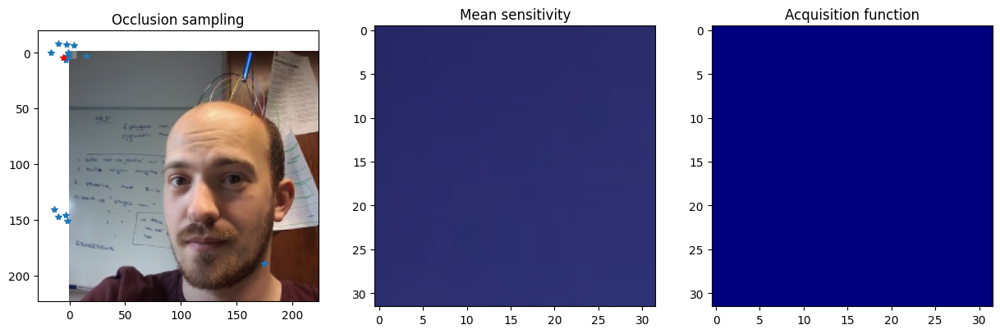

2025-10-12 12:08:49 | PID 576816 | RSS   294.9 MB | Plot updated
2025-10-12 12:08:49 | PID 576816 | RSS   294.9 MB | ITER 1 start | len(Xm)=17 | len(fm_dict)=6
2025-10-12 12:08:49 | PID 576816 | RSS   294.9 MB | Occlusion applied: grid=(28.00,30.00,4.00,6.00) → px=(168,168,224,224) img_size=(224,224) | patch=(56x56)
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
2025-10-12 12:08:55 | PID 576816 | RSS   294.9 MB | VLM call OK in 5.77s; keys=['Image_Demo_ethnicity_Category', 'Image_Demo_age_Category', 'Image_Demo_sex_Category', 'Image_Demo_highest_educational_qualification_Category', 'Image_Demo_household_income_bracket_Category']
2025-10-12 12:08:55 | PID 576816 | RSS   294.9 MB | Deltas computed
2025-10-12 12:08:55 | PID 576816 | RSS   294.9 MB | fm_mean built with shape (17,)
2025-10-12 12:08:55 | PID 576816 | RSS   294.9 MB | GP fitted
2025-10-12 12:08:55 | PID 576816 | RSS   297.9 MB | GP predict OK | mu.range=(0.0000,0.0000) | sig.range=(1.0000,1.0000)
2025-1

/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


2025-10-12 12:08:56 | PID 576816 | RSS   297.9 MB | ITER 2 start | len(Xm)=18 | len(fm_dict)=6
2025-10-12 12:08:56 | PID 576816 | RSS   297.9 MB | Occlusion applied: grid=(7.00,6.00,2.00,5.00) → px=(35,7,63,77) img_size=(224,224) | patch=(28x70)


KeyboardInterrupt: 

In [16]:
import os, time, psutil, traceback, tempfile, cv2, gc, atexit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from IPython import display

# ===============================================================
# CONFIG
# ===============================================================

log_path = os.path.expanduser("~/vlm_debug.log")
pid = os.getpid()
proc = psutil.Process(pid)

logf = open(log_path, "a", buffering=1)

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SAFE SETTINGS
# ===============================================================

SKIP_VLM = False
max_points = 60
plot_every = 3

# ===============================================================
# MAIN LOOP
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
L("=== Starting VLM saliency debug loop (fixed acquisition) ===")

for i in range(30):
    try:
        L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion to image (correct scaling) ---
        h_img, w_img = img.shape[:2]
        grid_pos = 32
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128
        L(f"Occlusion applied: grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) "
          f"→ px=({x1},{y1},{x2},{y2}) img_size=({w_img},{h_img}) | patch=({x2-x1}x{y2-y1})")

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
            L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                L(f"VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result)[:5]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise
        os.remove(tmp_path)

        # --- 6.3 Compute deltas for all features ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(delta)
        L("Deltas computed")

        # --- 6.4 Build fm_mean for GP ---
        fm_mean = np.array([
            np.mean([v[i] for v in fm_dict.values() if len(v) > i])
            for i in range(len(Xm))
        ])
        L(f"fm_mean built with shape {fm_mean.shape}")

        # --- 6.5 Normalize inputs for GP ---
        Xm_arr = np.array(Xm)
        X_norm = X / np.array([32, 32, 8, 8])
        Xm_norm = Xm_arr / np.array([32, 32, 8, 8])

        # --- 6.6 Fit GP ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        L("GP fitted")

        mu, sig = gp.predict(X_norm, return_std=True)
        L(f"GP predict OK | mu.range=({mu.min():.4f},{mu.max():.4f}) | "
          f"sig.range=({sig.min():.4f},{sig.max():.4f})")

        # --- 6.7 Acquisition function ---
        acq = mu + 1.5 * sig
        if np.allclose(acq, acq[0]):
            aq_bin = np.random.randint(len(X))
            L(f"Acquisition flat — random choice {aq_bin}")
        else:
            aq_bin = int(np.argmax(acq))
        L(f"DEBUG: aq_bin={aq_bin} | max_acq={acq[aq_bin]:.4f} | mu_mean={mu.mean():.4f} | sig_mean={sig.mean():.4f}")

        # --- 6.8 Update next state ---
        state = X[aq_bin].astype(int)
        Xm.append(state + np.random.randn(4,) * [1, 1, 0.5, 0.5])
        L(f"New state selected {state.tolist()}, Xm len={len(Xm)}")

        # --- 6.9 Saliency map + visualization ---
        expected = 32 * 32 * 7 * 7
        if mu.size != expected:
            L(f"mu size mismatch ({mu.size}) — skipping plot")
            continue

        ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(32, 32, -1), -1)

        if i % plot_every == 0:
            ax[0].cla(); ax[1].cla(); ax[2].cla()
            ax[0].imshow(masked_img)
            ax[0].plot(np.array(Xm)[:-2, 1] * scale_x,
                       np.array(Xm)[:-2, 0] * scale_y, '*')
            ax[0].plot(np.array(Xm)[-2, 1] * scale_x,
                       np.array(Xm)[-2, 0] * scale_y, 'r*')
            ax[0].set_title("Occlusion sampling")

            ax[1].imshow(img)
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet")
            ax[1].set_title("Mean sensitivity")

            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet")
            ax[2].set_title("Acquisition function")

            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            L("Plot updated")

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

L("=== Loop completed normally ===")
logf.flush()


In [ ]:
#version 20:43

import os, time, psutil, traceback, tempfile, cv2, gc, atexit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from IPython import display

# ===============================================================
# CONFIG / LOGGING
# ===============================================================
log_path = os.path.expanduser("~/vlm_debug.log")
pid = os.getpid()
proc = psutil.Process(pid)

logf = open(log_path, "a", buffering=1)

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SETTINGS
# ===============================================================
SKIP_VLM = False
max_points = 60
plot_every = 3

# Debug toggles
DEBUG_PRINT_MASKED_RESULT = True
DEBUG_SAVE_MASKED = True
DEBUG_SAVE_EVERY = 10
DEBUG_VERBOSE_FM = True

# ===============================================================
# CREATE SAMPLING GRID WITH LARGER OCCLUSION WINDOWS
# ===============================================================
grid_pos = 32  # defines the grid density

xv, yv, wv, hv = np.meshgrid(
    np.linspace(8, 24, 24),  # x positions
    np.linspace(8, 24, 24),  # y positions
    np.linspace(4, 16, 7),   # mask widths
    np.linspace(4, 16, 7),   # mask heights
    indexing="ij"
)

X = np.vstack((xv.ravel(), yv.ravel(), wv.ravel(), hv.ravel())).T

# initialize state
state = X[np.random.randint(0, X.shape[0]), :].astype(float)
Xm = [state]

L(f"Initialized occlusion grid: X.shape={X.shape}, initial state={state}")

# ===============================================================
# SANITY CHECK — visualize initial mask
# ===============================================================
h_img, w_img = img.shape[:2]
scale_x = w_img / grid_pos
scale_y = h_img / grid_pos
x0, y0, ww, hh = state
x1 = int(max(x0*scale_x - ww*scale_x, 0))
x2 = int(min(x0*scale_x + ww*scale_x, w_img))
y1 = int(max(y0*scale_y - hh*scale_y, 0))
y2 = int(min(y0*scale_y + hh*scale_y, h_img))
mask_vis = img.copy()
mask_vis[y1:y2, x1:x2, :] = 128

plt.imshow(mask_vis)
plt.title("Sample occlusion mask (larger window)")
plt.show()

# ===============================================================
# MAIN LOOP
# ===============================================================
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i in range(30):
    try:
        L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion ---
        h_img, w_img = img.shape[:2]
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128

        L(f"Occlusion applied: grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) → px=({x1},{y1},{x2},{y2}) patch=({x2-x1}x{y2-y1})")

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))
        L(f"Saved occluded image to {tmp_path}")

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
            L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                L(f"VLM call OK in {time.time()-t0:.2f}s; found keys: {list(masked_result.keys())[:6]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise

        if DEBUG_PRINT_MASKED_RESULT:
            try:
                sample_items = list(masked_result.items())[:6]
                sample_str = ", ".join([f"{k}:{v}" for k, v in sample_items])
                L(f"masked_result sample: {sample_str}")
            except Exception as ex:
                L(f"Couldn't stringify masked_result: {ex}")

        try:
            os.remove(tmp_path)
        except Exception:
            pass

        # --- 6.3 Compute deltas ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(float(delta))

            if DEBUG_VERBOSE_FM:
                arr = np.array(fm_dict[key])
                L(f"fm_dict[{key}] len={len(arr)} mean={arr.mean():.3f} std={arr.std():.3f} last={arr[-1]:.3f}")

        # --- 6.4 Build fm_mean for GP ---
        if len(Xm) == 0:
            state = X[np.random.randint(0, X.shape[0]), :].astype(int)
            Xm.append(state)
            continue

        key_ref = list(fm_dict.keys())[0]
        fm_values_ref = fm_dict[key_ref]
        n = min(len(Xm), len(fm_values_ref))
        fm_mean = np.array(fm_values_ref[:n])

        Xm_arr = np.array(Xm)
        X_norm = X / np.array([32, 32, 8, 8])
        Xm_norm = Xm_arr / np.array([32, 32, 8, 8])

        # --- 6.5 Fit GP ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
            L(f"Truncated Xm to last {max_points} points")

        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        L("Shared GP fitted")

        mu, sig = gp.predict(X_norm, return_std=True)
        L(f"GP predict done | mu_range=({mu.min():.6f},{mu.max():.6f}) | sig_range=({sig.min():.6f},{sig.max():.6f})")

        # --- 6.6 Acquisition ---
        acq = mu + 1.5 * sig
        if np.allclose(acq, acq[0]):
            aq_bin = np.random.randint(len(X))
            L(f"Acquisition flat — random choice {aq_bin}")
        else:
            aq_bin = int(np.argmax(acq))
        L(f"Selected aq_bin={aq_bin}")

        # --- 6.7 Update next state ---
        state = X[aq_bin].astype(int)
        Xm.append(state + np.random.randn(4,) * np.array([1, 1, 0.5, 0.5]))
        L(f"Appended new state {state.tolist()} | Xm len={len(Xm)}")

        # --- 6.8 Visualization ---
        expected = 32 * 32 * 7 * 7
        if mu.size != expected:
            continue

        ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(32, 32, -1), -1)

        if i % plot_every == 0:
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
            x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
            y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

            for a in ax: a.cla()

            ax[0].imshow(masked_img, extent=[0, w_img, h_img, 0])
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].plot(x_last, y_last, 'r*')
            ax[0].set_title("Occlusion sampling")

            ax[1].imshow(img, extent=[0, w_img, h_img, 0])
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[1].set_title("Mean sensitivity")

            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[2].set_title("Acquisition function")

            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            L("Plot updated")

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

# --- Summary ---
L("=== Finished loop — fm_dict summary ===")
for k, v in fm_dict.items():
    arr = np.array(v)
    L(f"{k:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f} first5={np.round(arr[:5],6)}")

logf.flush()


ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 576 and the array at index 2 has size 49

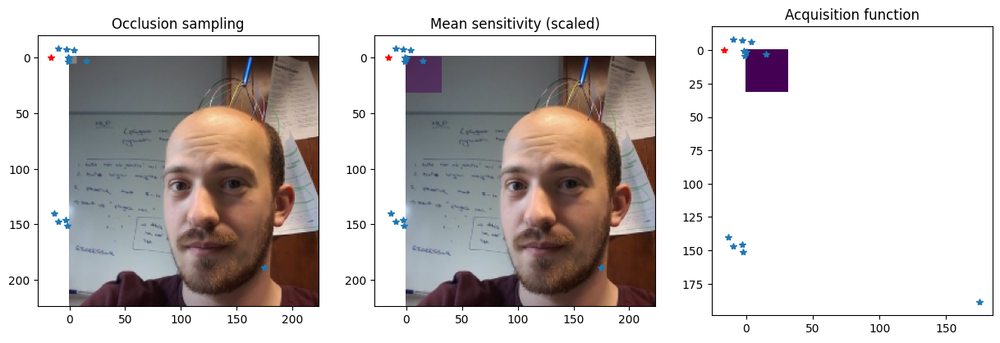

2025-10-12 12:03:27 | PID 576816 | RSS   289.0 MB | Plot updated (scaled coords)


KeyboardInterrupt: 

Exception ignored in: 'zmq.backend.cython._zmq.Frame.__dealloc__'
Traceback (most recent call last):
  File "zmq/backend/cython/_zmq.py", line 179, in zmq.backend.cython._zmq._check_rc
KeyboardInterrupt: 


2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | ITER 1 start | len(Xm)=14 | len(fm_dict)=6
2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | DEBUG: raw state=[0 0 1 1] type=<class 'numpy.ndarray'> dtype=int64
2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | DEBUG: unpacked grid coords -> x0=0.000, y0=0.000, ww=1.000, hh=1.000
2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | DEBUG: scale_x=7.000, scale_y=7.000
2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | DEBUG: scaled centers -> x0_px=0.000, y0_px=0.000
2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | DEBUG: scaled sizes   -> ww_px=7.000, hh_px=7.000
2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | Occlusion applied: grid=(0.00,0.00,1.00,1.00) → px=(0,0,7,7) img_size=(224,224) | patch_size=(7x7)
2025-10-12 12:03:28 | PID 576816 | RSS   291.7 MB | Saved occluded image to /tmp/tmp_0rhe_o7.jpg
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
2025-10-12 12:03:33 | PID 576816 | RSS   291.7 MB | V

/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | ITER 2 start | len(Xm)=15 | len(fm_dict)=6
2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | DEBUG: raw state=[0 0 1 1] type=<class 'numpy.ndarray'> dtype=int64
2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | DEBUG: unpacked grid coords -> x0=0.000, y0=0.000, ww=1.000, hh=1.000
2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | DEBUG: scale_x=7.000, scale_y=7.000
2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | DEBUG: scaled centers -> x0_px=0.000, y0_px=0.000
2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | DEBUG: scaled sizes   -> ww_px=7.000, hh_px=7.000
2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | Occlusion applied: grid=(0.00,0.00,1.00,1.00) → px=(0,0,7,7) img_size=(224,224) | patch_size=(7x7)
2025-10-12 12:03:33 | PID 576816 | RSS   292.3 MB | Saved occluded image to /tmp/tmpldrr2qa3.jpg
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
2025-10-12 12:03:38 | PID 576816 | RSS   292.3 MB | V

/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | ITER 3 start | len(Xm)=16 | len(fm_dict)=6
2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | DEBUG: raw state=[0 0 1 1] type=<class 'numpy.ndarray'> dtype=int64
2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | DEBUG: unpacked grid coords -> x0=0.000, y0=0.000, ww=1.000, hh=1.000
2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | DEBUG: scale_x=7.000, scale_y=7.000
2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | DEBUG: scaled centers -> x0_px=0.000, y0_px=0.000
2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | DEBUG: scaled sizes   -> ww_px=7.000, hh_px=7.000
2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | Occlusion applied: grid=(0.00,0.00,1.00,1.00) → px=(0,0,7,7) img_size=(224,224) | patch_size=(7x7)
2025-10-12 12:03:38 | PID 576816 | RSS   292.6 MB | Saved occluded image to /tmp/tmp2sj9kbxx.jpg


KeyboardInterrupt: 

In [15]:
import os, time, psutil, traceback, tempfile, cv2, gc, atexit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from IPython import display

# ===============================================================
# CONFIG
# ===============================================================

log_path = os.path.expanduser("~/vlm_debug.log")  # always in home dir
pid = os.getpid()
proc = psutil.Process(pid)

# open line-buffered log file so writes persist even on crash
logf = open(log_path, "a", buffering=1)

def L(msg):
    """Write timestamped message to log and stdout."""
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SAFE SETTINGS
# ===============================================================

SKIP_VLM = False        # set True to bypass actual model calls for debugging
max_points = 60         # limit GP size
plot_every = 3          # how often to refresh plot
X_downsample = 1        # reduce grid size if memory high

# ===============================================================
# MAIN LOOP
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
L("=== Starting VLM saliency debug loop ===")

for i in range(30):
    try:
        L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion to image (debug mode) ---

        h_img, w_img = img.shape[:2]
        grid_pos = 32  # the position grid resolution

        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        # Debug: inspect what "state" actually is
        L(f"DEBUG: raw state={state} type={type(state)} dtype={getattr(state, 'dtype', None)}")

        try:
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        except Exception as ex:
            L(f"ERROR: Failed to unpack state {state}: {ex}")
            raise

        L(f"DEBUG: unpacked grid coords -> x0={x0:.3f}, y0={y0:.3f}, ww={ww:.3f}, hh={hh:.3f}")

        # Scale all to pixel coordinates
        x0_px = x0 * scale_x
        y0_px = y0 * scale_y
        ww_px = ww * scale_x
        hh_px = hh * scale_y

        L(f"DEBUG: scale_x={scale_x:.3f}, scale_y={scale_y:.3f}")
        L(f"DEBUG: scaled centers -> x0_px={x0_px:.3f}, y0_px={y0_px:.3f}")
        L(f"DEBUG: scaled sizes   -> ww_px={ww_px:.3f}, hh_px={hh_px:.3f}")

        # Clip to image bounds
        x1 = int(max(x0_px - ww_px, 0))
        y1 = int(max(y0_px - hh_px, 0))
        x2 = int(min(x0_px + ww_px, w_img))
        y2 = int(min(y0_px + hh_px, h_img))

        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128

        L(f"Occlusion applied: grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) → "
        f"px=({x1},{y1},{x2},{y2}) img_size=({w_img},{h_img}) "
        f"| patch_size=({x2-x1}x{y2-y1})")



        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))
        L(f"Saved occluded image to {tmp_path}")

        # --- 6.3 Query the VLM ---
        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": 0.5
                for d in demo_features
            }
            L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                L(f"VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result)[:5]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise
        try:
            os.remove(tmp_path)
            L("Temp file removed")
        except Exception as ex:
            L(f"Warning: temp file removal failed {tmp_path}: {ex}")

        # --- 6.4 Compute deltas for all demo features ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                L(f"Missing base/masked for {key}")
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(delta)
        L("Deltas computed")

        # --- 6.5 Build fm_mean vector for GP training ---
        fm_mean = np.array([
            np.mean([v[i] for v in fm_dict.values() if len(v) > i])
            for i in range(len(Xm))
        ])
        L(f"fm_mean built with shape {fm_mean.shape}")

        # --- 6.6 Fit Gaussian Process ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
            L(f"Truncated Xm to last {max_points} points")

        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(np.array(Xm), np.array(fm_mean))
        L("GP fitted")

        # --- 6.7 Predict over grid X ---
        try:
            if X_downsample > 1:
                mu, sig = gp.predict(X[::X_downsample], return_std=True)
            else:
                mu, sig = gp.predict(X, return_std=True)
            L(f"GP predict OK | mu.shape={mu.shape} | sig.shape={sig.shape}")
        except MemoryError:
            L("MemoryError during GP.predict — likely OOM")
            break

        # --- 6.8 Select next occlusion state ---
        L("About to run argmax for next state")
        aq_bin = np.argmax(1.5 * sig + mu)
        state = X[aq_bin].astype(int)
        L(f"DEBUG: selected aq_bin={aq_bin} | new state={state.tolist()}")
        Xm.append(state + np.random.randn(4,) * [1, 1, 0.5, 0.5])
        L(f"Appended new state {state}, Xm length={len(Xm)}")

        # --- 6.9 Build saliency map and visualize occasionally ---
        expected = 32 * 32 * 7 * 7
        if mu.size != expected:
            L(f"mu size {mu.size} != expected {expected} — skipping plot")
            continue

        ov = mu.reshape(32, 32, 7, 7)
        ov = np.mean(ov, axis=(-1, -2))

        if i % plot_every == 0:
            sxy = np.sum(sig.reshape(32, 32, -1), -1)
            ax[0].cla(); ax[1].cla(); ax[2].cla()

            ax[0].imshow(masked_img)
            ax[0].plot(np.array(Xm)[:-2, 1] * scale_x,
                    np.array(Xm)[:-2, 0] * scale_y, '*')
            ax[0].plot(np.array(Xm)[-2, 1] * scale_x,
                    np.array(Xm)[-2, 0] * scale_y, 'r*')
            ax[0].set_title("Occlusion sampling")

            ax[1].imshow(img)
            ax[1].imshow(ov.T, alpha=0.5)
            ax[1].plot(np.array(Xm)[:-2, 1] * scale_x,
                    np.array(Xm)[:-2, 0] * scale_y, '*')
            ax[1].plot(np.array(Xm)[-2, 1] * scale_x,
                    np.array(Xm)[-2, 0] * scale_y, 'r*')
            ax[1].set_title("Mean sensitivity (scaled)")

            ax[2].imshow(5 * sxy.T + ov.T)
            ax[2].plot(np.array(Xm)[:-2, 1] * scale_x,
                    np.array(Xm)[:-2, 0] * scale_y, '*')
            ax[2].plot(np.array(Xm)[-2, 1] * scale_x,
                    np.array(Xm)[-2, 0] * scale_y, 'r*')
            ax[2].set_title("Acquisition function")

            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            L("Plot updated (scaled coords)")


        gc.collect()  # release memory occasionally

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

L("=== Loop completed normally ===")
logf.flush()


In [1]:
import psutil, os, time, traceback
process = psutil.Process(os.getpid())

def log_status(stage):
    rss = process.memory_info().rss / (1024 ** 2)  # MB
    print(f"[{time.strftime('%H:%M:%S')}] Stage: {stage:25s} | RSS: {rss:7.1f} MB")


In [ ]:
import time, psutil, os, traceback
pid = os.getpid()
proc = psutil.Process(pid)
logf = open("debug.log", "a", buffering=1)  # line buffered

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss/(1024**2)
    logf.write(f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}\n")
    print(msg)

# OPTIONAL: toggle to True to skip network/VLM and test locally
SKIP_VLM = False

fig, ax = plt.subplots(1,3,figsize=(15,5))
L("Starting loop")

for i in range(150):
    try:
        L(f"ITER {i} start; len(Xm)={len(Xm)}; len(fm_dict)={len(fm_dict)}")

        # occlusion coords
        try:
            x0, y0, ww, hh = [int(v) for v in np.ravel(state)]
        except Exception as ex:
            L(f"Bad state {state}: {ex}")
            raise

        x1 = max(x0 - ww, 0); y1 = max(y0 - hh, 0)
        x2 = min(x0 + ww, w);  y2 = min(y0 + hh, h)
        L(f"coords: {(x1,y1,x2,y2)} img.shape={getattr(img,'shape',None)}")

        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128
        L("masked_img created")

        # tmp file write
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        ok = cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))
        L(f"wrote tmp image {tmp_path} ok={ok}")
        if not ok:
            raise RuntimeError("cv2.imwrite failed")

        # VLM call (stub if requested)
        if SKIP_VLM:
            masked_result = {f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": 0.5 for d in demo_features}
            L("SKIP_VLM enabled: using fake masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                t1 = time.time()
                L(f"VLM returned in {t1-t0:.2f}s; keys={list(masked_result.keys())[:5]}")
            except Exception as ex:
                L(f"Exception from VLM call: {ex}")
                raise
        try:
            os.remove(tmp_path)
            L("tmp file removed")
        except Exception as ex:
            L(f"Failed to remove tmp file {tmp_path}: {ex}")

        # compute deltas
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                L(f"Missing base or masked for {key}: base={base_score}, masked={masked_score}")
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(delta)
        L("deltas computed")

        # Build fm_mean carefully
        try:
            fm_mean = np.array([np.mean([v[i] for v in fm_dict.values() if len(v) > i]) for i in range(len(Xm))])
            L(f"fm_mean shape {fm_mean.shape}")
        except Exception as ex:
            L(f"Failed fm_mean build: {ex}")
            raise

        # slice Xm to limit GP complexity
        max_points = 60
        if len(Xm) > max_points:
            L(f"Truncating Xm from {len(Xm)} to {max_points}")
            Xm = Xm[-max_points:]

        # fit GP (wrapped)
        try:
            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(np.array(Xm), np.array(fm_mean))
            L("GP fit done")
        except MemoryError:
            L("MemoryError during GP.fit")
            raise
        except Exception as ex:
            L(f"GP fit exception: {ex}")
            raise

        mu, sig = gp.predict(X, return_std=True)
        L(f"GP predict done mu.shape={mu.shape} sig.shape={sig.shape}")
        # === Select next occlusion point and record it ===
        try:
            aq_bin = np.argmax(1.5 * sig.reshape(-1, 1) + mu)
            state = X[aq_bin].astype(int)
            Xm.append(state + np.random.randn(4,) * [1, 1, 0.5, 0.5])  # store occlusion coordinates
            L(f"Appended new state: {state}, Xm length now {len(Xm)}")
        except Exception as ex:
            L(f"Failed to select next occlusion state: {ex}")
            raise

        # reshaping check
        expected = 32*32*7*7
        L(f"mu.size={mu.size} expected={expected}")
        if mu.size != expected:
            L("mu size mismatch; skipping reshape and plotting to avoid crash")
            break

        ov = mu.reshape(32,32,7,7)
        ov = np.mean(ov, axis=-1)
        ov = np.mean(ov, axis=-1)

        # plotting (reduced frequency)
        if i % 3 == 0:
            ax[0].cla(); ax[1].cla(); ax[2].cla()
            ax[0].imshow(masked_img)
            ax[1].imshow(img); ax[1].imshow(ov.T, alpha=0.5)
            sxy = np.sum(sig.reshape(32,32,-1), -1)
            ax[2].imshow(5*sxy.T + ov.T)
            display.display(fig)
            display.clear_output(wait=True)
            plt.pause(0.01)
            L("plotted")

    except Exception as e:
        L(f"ITER {i} exception: {traceback.format_exc()}")
        break

logf.close()


Starting loop
ITER 0 start; len(Xm)=1; len(fm_dict)=6
coords: (0, 5, 13, 17) img.shape=(224, 224, 3)
masked_img created
wrote tmp image /tmp/tmp38zliz51.jpg ok=True
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
VLM returned in 4.91s; keys=['Image_Demo_ethnicity_Category', 'Image_Demo_age_Category', 'Image_Demo_sex_Category', 'Image_Demo_highest_educational_qualification_Category', 'Image_Demo_household_income_bracket_Category']
tmp file removed
deltas computed
fm_mean shape (1,)
GP fit done
GP predict done mu.shape=(50176,) sig.shape=(50176,)


In [ ]:
fig, ax = plt.subplots(1,3,figsize=(15,5))
for i in range(30):
    try:
        # --- 6.1 Apply occlusion to image ---
        x0, y0, ww, hh = [int(v) for v in np.ravel(state)]
        x1 = max(x0 - ww, 0)
        y1 = max(y0 - hh, 0)
        x2 = min(x0 + ww, w)
        y2 = min(y0 + hh, h)


        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128  # gray patch  

        # Save temporary occluded image
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        # --- 6.2 Query Azure VLM once for all features ---
        _, _, masked_result = infer_image_demographics_with_retry(
            image_source=tmp_path,
            model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
            demo_features=demo_features,
            prefix="Image_Demo",
        )
        os.remove(tmp_path)

        # --- 6.3 Compute deltas for all features ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                print("base score or masked score doesn't exisit")
                continue
            delta = base_score - masked_score
            fm_dict[key].append(delta)   

        # --- 6.4 Fit GP and select next region ---
        gp = GaussianProcessRegressor(kernel=Matern(length_scale_bounds=[1,5],length_scale=[3,3,2,2],nu=1.5),alpha=0.05)
        # Note: atm we are fitting the GP on the mean delta across features, but maybe we should do it per feature, we can test this out later
        fm_mean = np.array([np.mean([v[i] for v in fm_dict.values() if len(v) > i]) for i in range(len(Xm))])
        gp.fit(np.array(Xm),np.array(fm_mean))
        
        mu,sig = gp.predict(X,return_std=True)
        
        # Choose next blanking point, trading off exploration and exploitation
        aq_bin = np.argmax(1.5*sig.reshape(-1,1)+mu)
        
        state = X[aq_bin].astype(int)
        
        Xm.append(state+np.random.randn(4,)*[1,1,0.5,0.5]) # Add some jitter so we aren't stuck to grid
        
        # --- 6.5 Build saliency maps for all features ---
        ov = mu.reshape(32,32,7,7) # Generate saliency map (change in probability over all params)
        
        # Take expectation over box sizes
        ov = np.mean(ov,axis=-1)
        ov = np.mean(ov,axis=-1)
        # if i % 3 == 0: 
            # Plot every 10th sample
            ax[0].cla()
            ax[0].imshow(masked_img)
            ax[0].plot(np.array(Xm)[:-2,1],np.array(Xm)[:-2,0],'*')
            ax[0].plot(np.array(Xm)[-2,1],np.array(Xm)[-2,0],'r*')


            ax[1].cla()
            ax[1].imshow(img)
            ax[1].imshow(ov.T,alpha=0.5)
            ax[1].plot(np.array(Xm)[:-2,1],np.array(Xm)[:-2,0],'*')
            ax[1].plot(np.array(Xm)[-2,1],np.array(Xm)[-2,0],'r*')
            ax[1].set_title('Mean sensitivity(all features combined)')

            sxy = np.sum(sig.reshape(32,32,-1),-1)

            ax[2].cla()
            ot = ax[2].imshow(5*sxy.T+ov.T)
            ax[2].plot(np.array(Xm)[:-2,1],np.array(Xm)[:-2,0],'*')
            ax[2].plot(np.array(Xm)[-2,1],np.array(Xm)[-2,0],'r*')
            ax[2].set_title('Acquisition function')
            display.display(plt.gcf())
            display.clear_output(wait=True)
        plt.pause(0.01)
    
    except Exception as e:
        print(f"Iteration {i} failed: {e}")
        break

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


In [18]:
# ============================================================
# 7. Fit one GP per demographic feature for independent saliency maps
# ============================================================

saliency_maps = {}

for key, fm_values in fm_dict.items():
    if len(fm_values) == 0:
        continue

    # Fit Gaussian Process for this feature
    gp = GaussianProcessRegressor(
        kernel=Matern(length_scale_bounds=[1, 5],
                      length_scale=[3, 3, 2, 2],
                      nu=1.5),
        alpha=0.05,
    )

    # Same occlusion positions (Xm), feature-specific deltas (fm_values)
    gp.fit(np.array(Xm[:len(fm_values)]), np.array(fm_values))

    # Predict saliency surface for this feature
    mu, _ = gp.predict(X, return_std=True)
    mu_map = mu.reshape(32, 32, 7, 7)
    mu_map = np.mean(mu_map, axis=(-1, -2))  # expectation over window sizes
    saliency_maps[key] = mu_map


ValueError: Found input variables with inconsistent numbers of samples: [48, 49]

In [11]:
print("len(Xm):", len(Xm))
print("len(fm_values):", len(fm_values))
print("Xm[:len(fm_values)] shape:", np.array(Xm[:len(fm_values)]).shape)
print("fm_values shape:", np.array(fm_values).shape)


len(Xm): 1
len(fm_values): 30
Xm[:len(fm_values)] shape: (1, 4)
fm_values shape: (30,)


In [19]:
# ============================================================
# 8. Visualize all feature saliency maps
# ============================================================
num_features = len(saliency_maps)
cols = 4
rows = int(np.ceil(num_features / cols))
plt.figure(figsize=(4 * cols, 4 * rows))
for i, (key, smap) in enumerate(saliency_maps.items()):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.imshow(smap.T, alpha=0.5)
    plt.axis("off")
    plt.title(key.replace(f"Image_Demo_", "").replace("_Speculation", "").replace("_", " "))
plt.tight_layout()
plt.show()

<Figure size 1600x0 with 0 Axes>

In [20]:
# ============================================================
# 8. Visualize all feature saliency maps (overlay on original image)
# ============================================================
from skimage.transform import resize

num_features = len(saliency_maps)
cols = 4
rows = int(np.ceil(num_features / cols))
plt.figure(figsize=(4 * cols, 4 * rows))

for i, (key, smap) in enumerate(saliency_maps.items()):
    # 1️⃣ Normalize the saliency map for visibility
    smap_norm = (smap - smap.min()) / (smap.max() - smap.min() + 1e-8)

    # 2️⃣ Resize saliency map to match original image dimensions
    smap_resized = resize(
        smap_norm,
        (img.shape[0], img.shape[1]),
        order=1,
        preserve_range=True,
        anti_aliasing=True
    )

    # 3️⃣ Plot overlay
    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.imshow(smap_resized, cmap="jet", alpha=0.5)
    plt.axis("off")

    # 4️⃣ Clean up the title
    title = (key.replace("Image_Demo_", "")
                .replace("_Speculation", "")
                .replace("_", " "))
    plt.title(title)

plt.tight_layout()
plt.show()


<Figure size 1600x0 with 0 Axes>

Plotting saliency for Image_Demo_ethnicity_Speculation


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


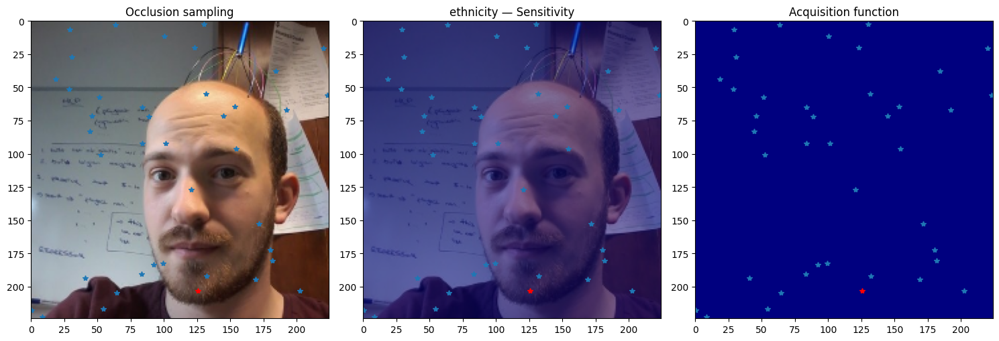

Plotting saliency for Image_Demo_age_Speculation


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


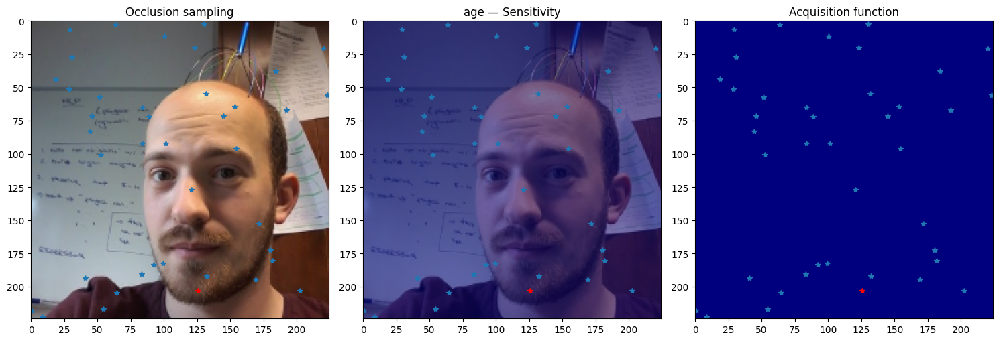

Plotting saliency for Image_Demo_sex_Speculation


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


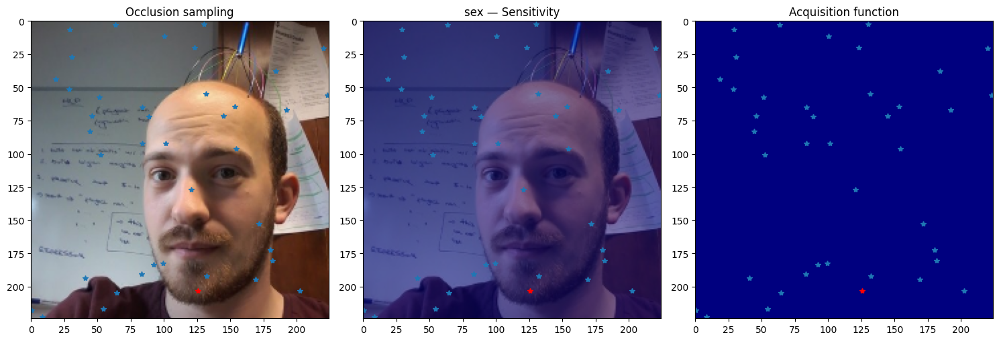

Plotting saliency for Image_Demo_highest_educational_qualification_Speculation


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


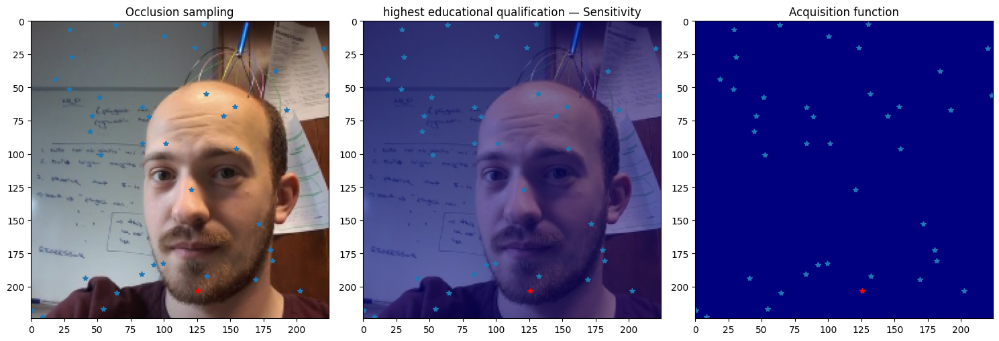

Plotting saliency for Image_Demo_household_income_bracket_Speculation


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


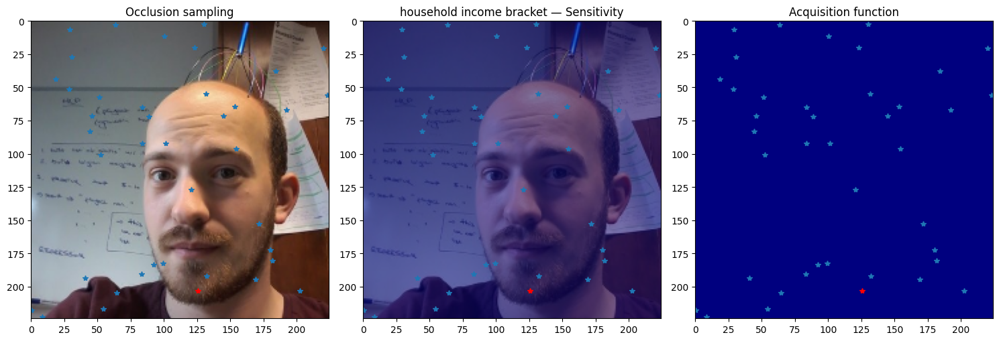

Plotting saliency for Image_Demo_partisan_loyalties_Speculation


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


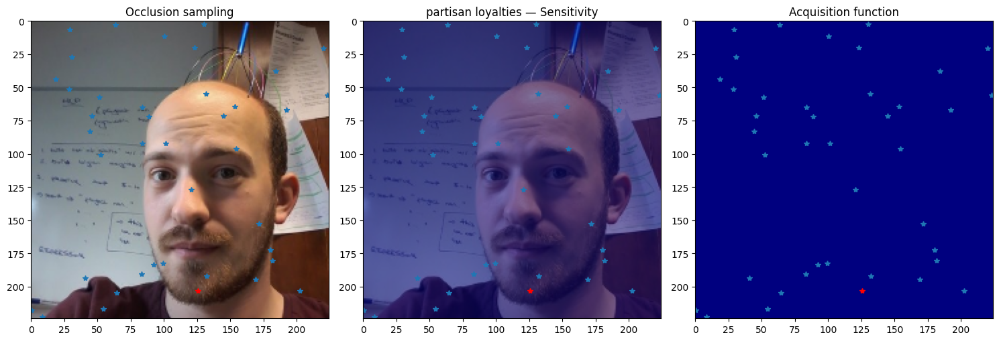

In [10]:
# ============================================================
# 9. Visualize saliency and acquisition per demographic feature (aligned)
# ============================================================

import matplotlib.pyplot as plt
from IPython import display
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
import numpy as np

h_img, w_img = img.shape[:2]
scale_x = w_img / 32.0
scale_y = h_img / 32.0

for key, fm_values in fm_dict.items():
    if len(fm_values) < 2:
        continue  # skip if not enough data

    print(f"Plotting saliency for {key}")

    # === Refit GP for this feature ===
    n = min(len(Xm), len(fm_values))
    X_train = np.array(Xm[:n]) / np.array([32, 32, 8, 8])  # normalized like in main loop
    y_train = np.array(fm_values[:n])
    gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
    gp.fit(X_train, y_train)

    # === Predict saliency surface ===
    X_norm = X / np.array([32, 32, 8, 8])
    mu, sig = gp.predict(X_norm, return_std=True)
    ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
    sxy = np.sum(sig.reshape(32, 32, -1), -1)

    # === Scale coordinates for plotting ===
    x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
    y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
    x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
    y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

    # === Plot with consistent coordinate extents ===
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    # 1️⃣ Occlusion sampling
    ax[0].imshow(img, extent=[0, w_img, h_img, 0])
    ax[0].plot(x_plot, y_plot, '*')
    ax[0].plot(x_last, y_last, 'r*')
    ax[0].set_xlim(0, w_img)
    ax[0].set_ylim(h_img, 0)
    ax[0].set_title("Occlusion sampling")

    # 2️⃣ Sensitivity overlay
    ax[1].imshow(img, extent=[0, w_img, h_img, 0])
    ax[1].imshow(ov.T, alpha=0.5, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[1].plot(x_plot, y_plot, '*')
    ax[1].plot(x_last, y_last, 'r*')
    ax[1].set_xlim(0, w_img)
    ax[1].set_ylim(h_img, 0)
    ax[1].set_title(f"{key.replace('Image_Demo_', '').replace('_Speculation', '').replace('_', ' ')} — Sensitivity")

    # 3️⃣ Acquisition function
    ax[2].imshow(5 * sxy.T + ov.T, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[2].plot(x_plot, y_plot, '*')
    ax[2].plot(x_last, y_last, 'r*')
    ax[2].set_xlim(0, w_img)
    ax[2].set_ylim(h_img, 0)
    ax[2].set_title("Acquisition function")

    plt.tight_layout()
    display.display(fig)
    plt.close(fig)



=== Plotting saliency for Image_Demo_ethnicity_Speculation ===
[DEBUG] Image_Demo_ethnicity_Speculation y_train stats: mean=-11.0000, std=13.0000, min=-50.0000, max=0.0000
[DEBUG] Image_Demo_ethnicity_Speculation mu range=(0.0000, 0.0000) | sig range=(1.0000, 1.0000)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


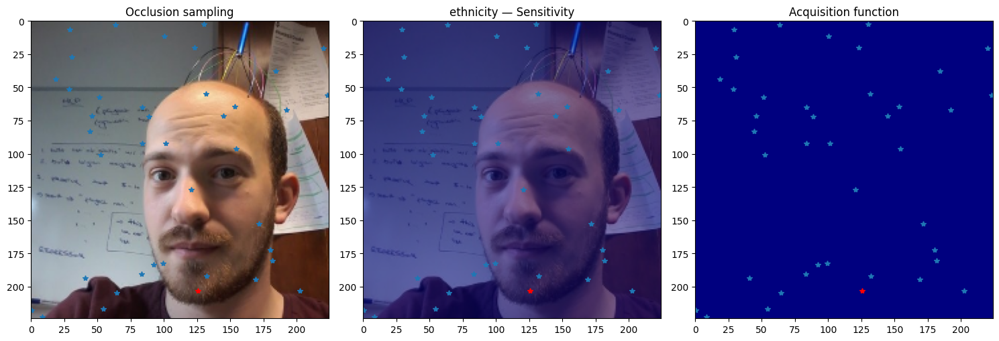


=== Plotting saliency for Image_Demo_age_Speculation ===
[DEBUG] Image_Demo_age_Speculation y_train stats: mean=-10.0000, std=7.7460, min=-30.0000, max=0.0000


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Image_Demo_age_Speculation mu range=(0.0000, 0.0000) | sig range=(1.0000, 1.0000)


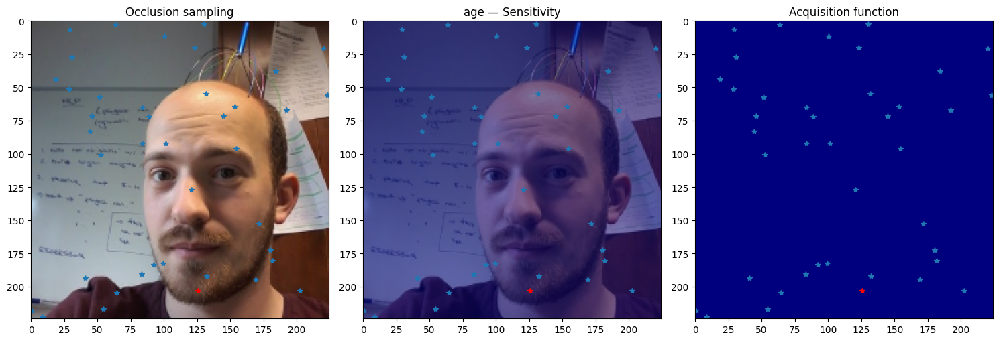


=== Plotting saliency for Image_Demo_sex_Speculation ===
[DEBUG] Image_Demo_sex_Speculation y_train stats: mean=-4.7500, std=5.9108, min=-20.0000, max=0.0000
[DEBUG] Image_Demo_sex_Speculation mu range=(0.0000, 0.0000) | sig range=(1.0000, 1.0000)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


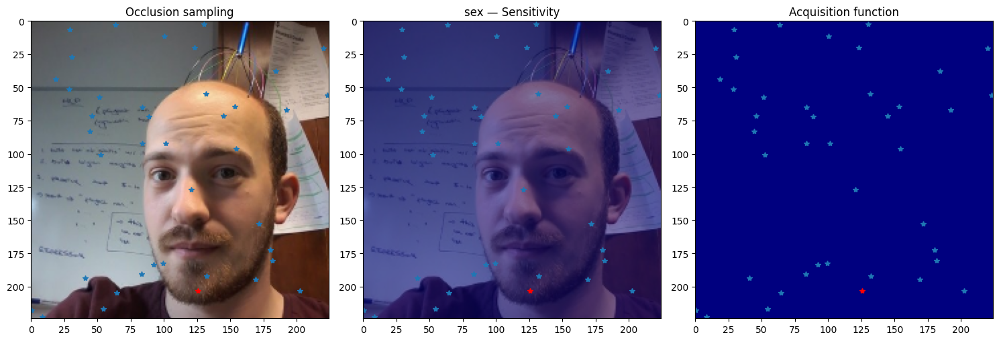


=== Plotting saliency for Image_Demo_highest_educational_qualification_Speculation ===
[DEBUG] Image_Demo_highest_educational_qualification_Speculation y_train stats: mean=-1.7500, std=13.7636, min=-50.0000, max=20.0000


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Image_Demo_highest_educational_qualification_Speculation mu range=(0.0000, 0.0000) | sig range=(1.0000, 1.0000)


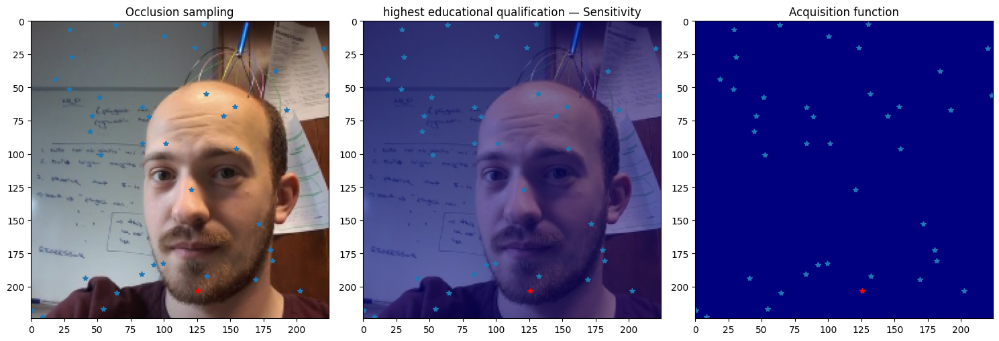


=== Plotting saliency for Image_Demo_household_income_bracket_Speculation ===
[DEBUG] Image_Demo_household_income_bracket_Speculation y_train stats: mean=-16.7500, std=9.8457, min=-40.0000, max=0.0000
[DEBUG] Image_Demo_household_income_bracket_Speculation mu range=(0.0000, 0.0000) | sig range=(1.0000, 1.0000)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


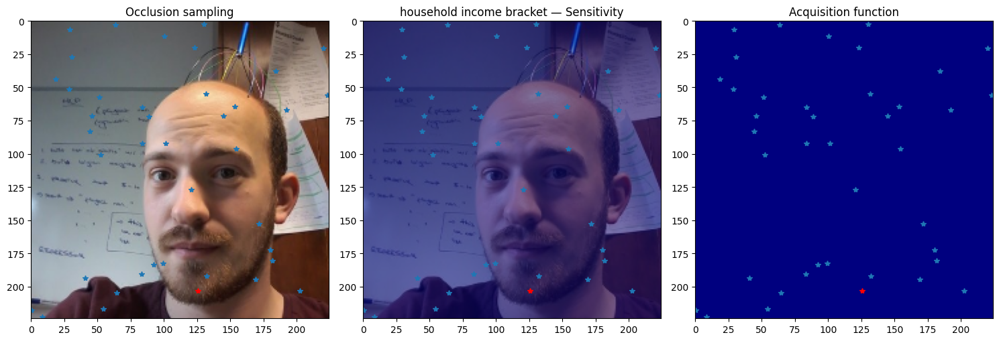


=== Plotting saliency for Image_Demo_partisan_loyalties_Speculation ===
[DEBUG] Image_Demo_partisan_loyalties_Speculation y_train stats: mean=1.0000, std=3.0000, min=0.0000, max=10.0000


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Image_Demo_partisan_loyalties_Speculation mu range=(0.0000, 0.0000) | sig range=(1.0000, 1.0000)


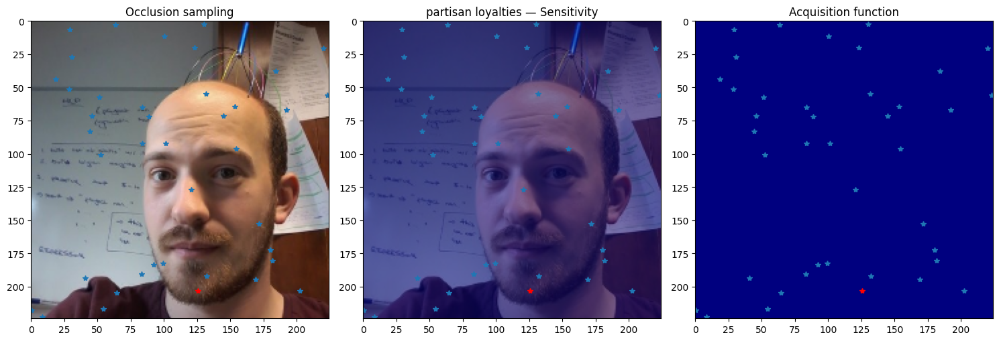

In [11]:
# ============================================================
# 9. Visualize saliency and acquisition per demographic feature (aligned)
# ============================================================

import matplotlib.pyplot as plt
from IPython import display
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
import numpy as np

h_img, w_img = img.shape[:2]
scale_x = w_img / 32.0
scale_y = h_img / 32.0

for key, fm_values in fm_dict.items():
    if len(fm_values) < 2:
        continue  # skip if not enough data

    print(f"\n=== Plotting saliency for {key} ===")
    n = min(len(Xm), len(fm_values))
    X_train = np.array(Xm[:n]) / np.array([32, 32, 8, 8])
    y_train = np.array(fm_values[:n])

    # 🔍 Debug stats
    print(f"[DEBUG] {key} y_train stats: mean={y_train.mean():.4f}, "
          f"std={y_train.std():.4f}, min={y_train.min():.4f}, max={y_train.max():.4f}")

    # Normalize to help GP capture shape, not magnitude
    y_train = (y_train - y_train.mean()) / (y_train.std() + 1e-8)

    gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
    gp.fit(X_train, y_train)

    X_norm = X / np.array([32, 32, 8, 8])
    mu, sig = gp.predict(X_norm, return_std=True)
    print(f"[DEBUG] {key} mu range=({mu.min():.4f}, {mu.max():.4f}) "
          f"| sig range=({sig.min():.4f}, {sig.max():.4f})")

    ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
    sxy = np.sum(sig.reshape(32, 32, -1), -1)

    # Scale coords
    x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
    y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
    x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
    y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    ax[0].imshow(img, extent=[0, w_img, h_img, 0])
    ax[0].plot(x_plot, y_plot, '*')
    ax[0].plot(x_last, y_last, 'r*')
    ax[0].set_xlim(0, w_img)
    ax[0].set_ylim(h_img, 0)
    ax[0].set_title("Occlusion sampling")

    ax[1].imshow(img, extent=[0, w_img, h_img, 0])
    ax[1].imshow(ov.T, alpha=0.5, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[1].plot(x_plot, y_plot, '*')
    ax[1].plot(x_last, y_last, 'r*')
    ax[1].set_xlim(0, w_img)
    ax[1].set_ylim(h_img, 0)
    ax[1].set_title(f"{key.replace('Image_Demo_', '').replace('_Speculation', '').replace('_', ' ')} — Sensitivity")

    ax[2].imshow(5 * sxy.T + ov.T, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[2].plot(x_plot, y_plot, '*')
    ax[2].plot(x_last, y_last, 'r*')
    ax[2].set_xlim(0, w_img)
    ax[2].set_ylim(h_img, 0)
    ax[2].set_title("Acquisition function")

    plt.tight_layout()
    display.display(fig)
    plt.close(fig)



=== Plotting saliency for Image_Demo_ethnicity_Speculation ===
[DEBUG] y_train stats: mean=-11.0000, std=13.0000, min=-50.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.019,1.997), y0_range=(0.003,2.000), w_range=(0.092,2.000), h_range=(0.076,2.191)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] mu range=(0.0000,0.0000) | sig range=(1.0000,1.0000)


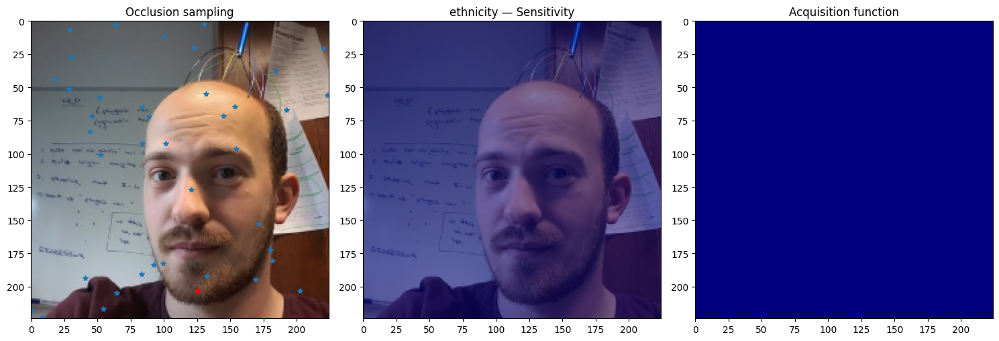


=== Plotting saliency for Image_Demo_age_Speculation ===
[DEBUG] y_train stats: mean=-10.0000, std=7.7460, min=-30.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.019,1.997), y0_range=(0.003,2.000), w_range=(0.092,2.000), h_range=(0.076,2.191)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] mu range=(0.0000,0.0000) | sig range=(1.0000,1.0000)


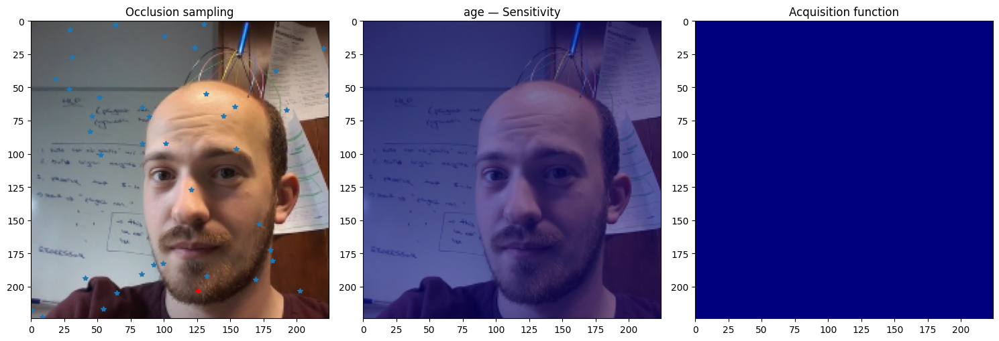


=== Plotting saliency for Image_Demo_sex_Speculation ===
[DEBUG] y_train stats: mean=-4.7500, std=5.9108, min=-20.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.019,1.997), y0_range=(0.003,2.000), w_range=(0.092,2.000), h_range=(0.076,2.191)
[DEBUG] mu range=(-0.0000,-0.0000) | sig range=(1.0000,1.0000)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


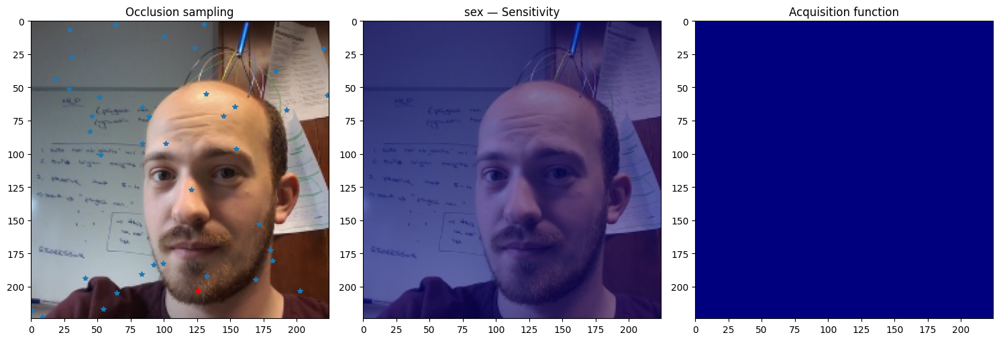


=== Plotting saliency for Image_Demo_highest_educational_qualification_Speculation ===
[DEBUG] y_train stats: mean=-1.7500, std=13.7636, min=-50.0000, max=20.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.019,1.997), y0_range=(0.003,2.000), w_range=(0.092,2.000), h_range=(0.076,2.191)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] mu range=(0.0000,0.0000) | sig range=(1.0000,1.0000)


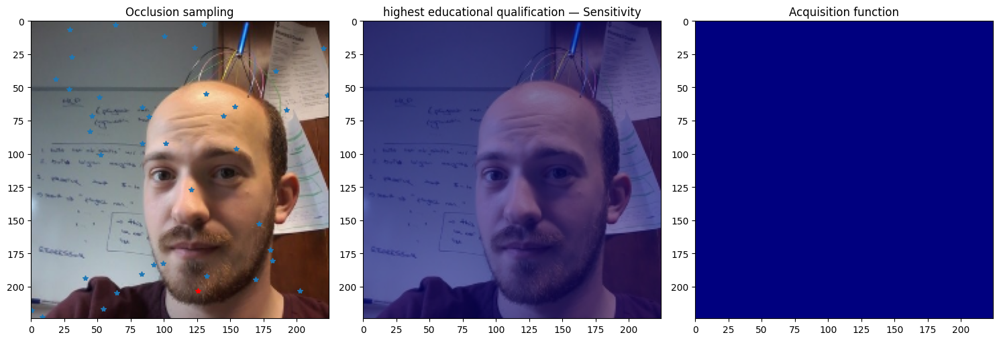


=== Plotting saliency for Image_Demo_household_income_bracket_Speculation ===
[DEBUG] y_train stats: mean=-16.7500, std=9.8457, min=-40.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.019,1.997), y0_range=(0.003,2.000), w_range=(0.092,2.000), h_range=(0.076,2.191)
[DEBUG] mu range=(0.0000,0.0000) | sig range=(1.0000,1.0000)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


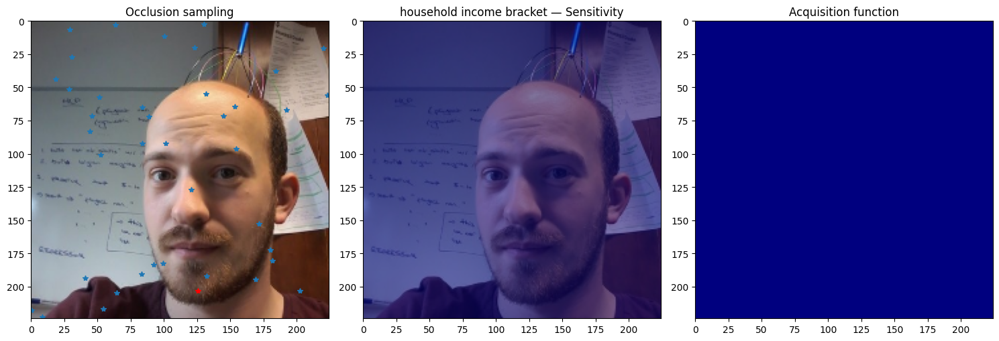


=== Plotting saliency for Image_Demo_partisan_loyalties_Speculation ===
[DEBUG] y_train stats: mean=1.0000, std=3.0000, min=0.0000, max=10.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.019,1.997), y0_range=(0.003,2.000), w_range=(0.092,2.000), h_range=(0.076,2.191)
[DEBUG] mu range=(0.0000,0.0000) | sig range=(1.0000,1.0000)


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


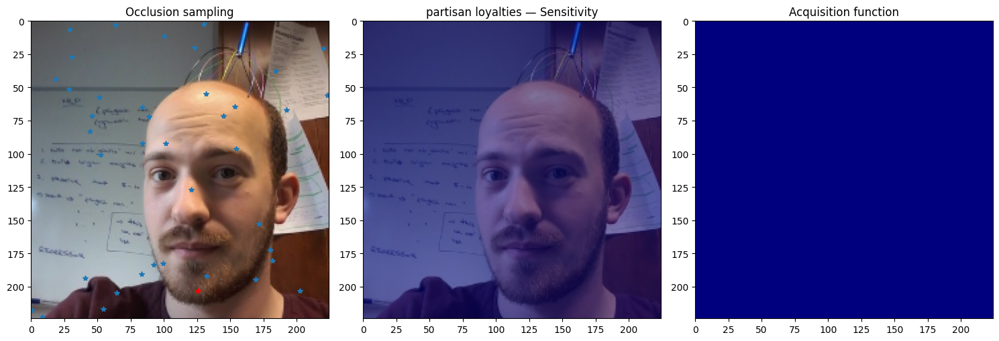

In [12]:
# ============================================================
# 9. Visualize saliency and acquisition per demographic feature (debug-enhanced)
# ============================================================

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
import matplotlib.pyplot as plt
from IPython import display
import numpy as np

h_img, w_img = img.shape[:2]
scale_x = w_img / 32.0
scale_y = h_img / 32.0

for key, fm_values in fm_dict.items():
    if len(fm_values) < 2:
        continue

    print(f"\n=== Plotting saliency for {key} ===")
    n = min(len(Xm), len(fm_values))
    X_train = np.array(Xm[:n]) / np.array([16, 16, 4, 4])  # adjust normalization
    y_train = np.array(fm_values[:n])

    print(f"[DEBUG] y_train stats: mean={y_train.mean():.4f}, std={y_train.std():.4f}, "
          f"min={y_train.min():.4f}, max={y_train.max():.4f}")
    print(f"[DEBUG] X_train stats: shape={X_train.shape}, "
          f"x0_range=({X_train[:,0].min():.3f},{X_train[:,0].max():.3f}), "
          f"y0_range=({X_train[:,1].min():.3f},{X_train[:,1].max():.3f}), "
          f"w_range=({X_train[:,2].min():.3f},{X_train[:,2].max():.3f}), "
          f"h_range=({X_train[:,3].min():.3f},{X_train[:,3].max():.3f})")

    y_train = (y_train - y_train.mean()) / (y_train.std() + 1e-8)

    kernel = Matern(length_scale_bounds=(1e-5, 100.0), nu=1.5)
    gp = GaussianProcessRegressor(kernel=kernel, alpha=0.01, normalize_y=True)
    gp.fit(X_train, y_train)

    X_norm = X / np.array([16, 16, 4, 4])
    mu, sig = gp.predict(X_norm, return_std=True)
    print(f"[DEBUG] mu range=({mu.min():.4f},{mu.max():.4f}) | sig range=({sig.min():.4f},{sig.max():.4f})")

    ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
    sxy = np.sum(sig.reshape(32, 32, -1), -1)

    # Scale for plotting
    x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
    y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
    x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
    y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img, extent=[0, w_img, h_img, 0])
    ax[0].plot(x_plot, y_plot, '*')
    ax[0].plot(x_last, y_last, 'r*')
    ax[0].set_xlim(0, w_img); ax[0].set_ylim(h_img, 0)
    ax[0].set_title("Occlusion sampling")

    ax[1].imshow(img, extent=[0, w_img, h_img, 0])
    ax[1].imshow(ov.T, alpha=0.5, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[1].set_xlim(0, w_img); ax[1].set_ylim(h_img, 0)
    ax[1].set_title(f"{key.replace('Image_Demo_', '').replace('_Speculation', '').replace('_', ' ')} — Sensitivity")

    ax[2].imshow(5 * sxy.T + ov.T, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[2].set_xlim(0, w_img); ax[2].set_ylim(h_img, 0)
    ax[2].set_title("Acquisition function")

    plt.tight_layout()
    display.display(fig)
    plt.close(fig)



=== Plotting saliency for Image_Demo_ethnicity_Speculation ===
[DEBUG] y_train stats: mean=-11.0000, std=13.0000, min=-50.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.149,15.973), y0_range=(0.025,16.000), w_range=(0.183,4.000), h_range=(0.152,4.382)
[DEBUG] mu mean=0.7791, std=0.0422, range=(0.0757,0.9854)
[DEBUG] sig mean=0.2561, std=0.0099, range=(0.0552,0.2600)


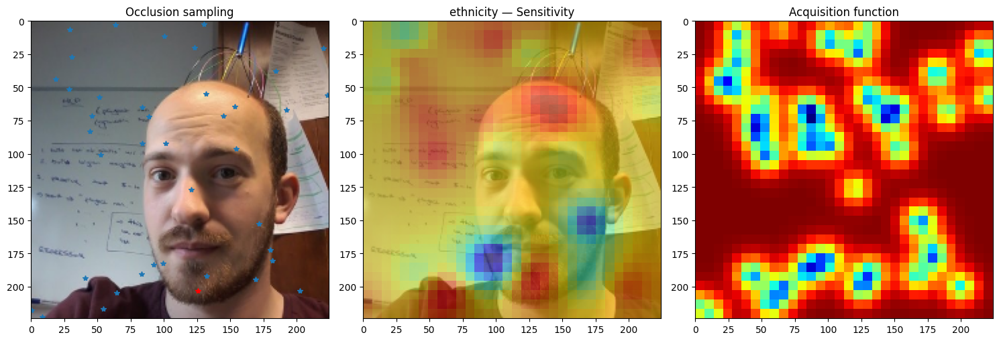


=== Plotting saliency for Image_Demo_age_Speculation ===
[DEBUG] y_train stats: mean=-10.0000, std=7.7460, min=-30.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.149,15.973), y0_range=(0.025,16.000), w_range=(0.183,4.000), h_range=(0.152,4.382)
[DEBUG] mu mean=0.6667, std=0.0000, range=(0.6667,0.6667)
[DEBUG] sig mean=0.2582, std=0.0000, range=(0.2582,0.2582)


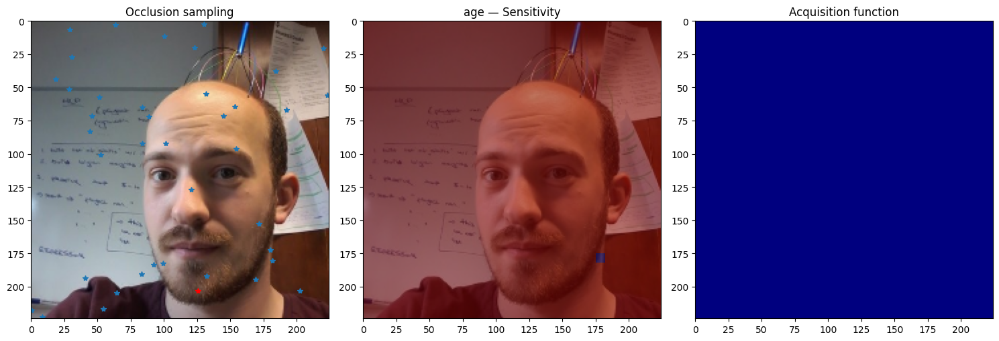


=== Plotting saliency for Image_Demo_sex_Speculation ===
[DEBUG] y_train stats: mean=-4.7500, std=5.9108, min=-20.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.149,15.973), y0_range=(0.025,16.000), w_range=(0.183,4.000), h_range=(0.152,4.382)
[DEBUG] mu mean=0.7625, std=0.0005, range=(0.6745,0.7908)
[DEBUG] sig mean=0.2955, std=0.0001, range=(0.2783,0.2955)


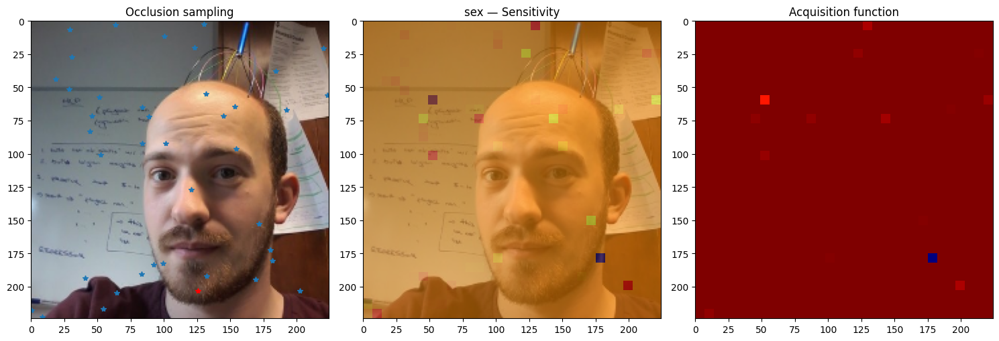


=== Plotting saliency for Image_Demo_highest_educational_qualification_Speculation ===
[DEBUG] y_train stats: mean=-1.7500, std=13.7636, min=-50.0000, max=20.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.149,15.973), y0_range=(0.025,16.000), w_range=(0.183,4.000), h_range=(0.152,4.382)
[DEBUG] mu mean=0.6840, std=0.0441, range=(0.0575,0.9796)
[DEBUG] sig mean=0.1914, std=0.0100, range=(0.0371,0.1966)


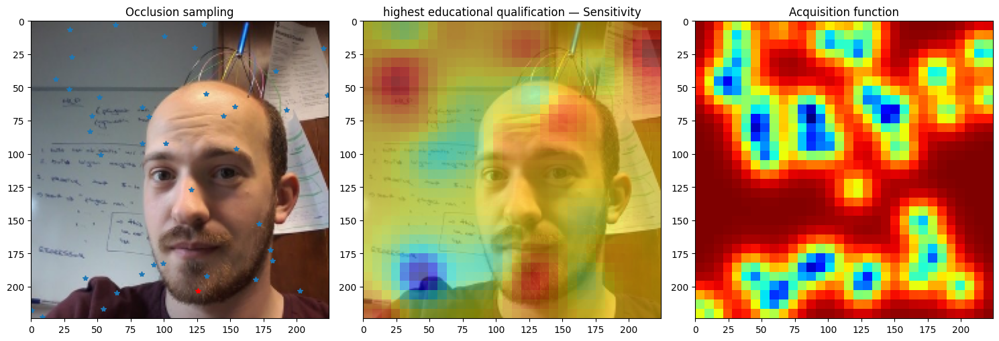


=== Plotting saliency for Image_Demo_household_income_bracket_Speculation ===
[DEBUG] y_train stats: mean=-16.7500, std=9.8457, min=-40.0000, max=0.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.149,15.973), y0_range=(0.025,16.000), w_range=(0.183,4.000), h_range=(0.152,4.382)
[DEBUG] mu mean=0.5812, std=0.0000, range=(0.5757,0.5823)
[DEBUG] sig mean=0.2461, std=0.0000, range=(0.2456,0.2461)


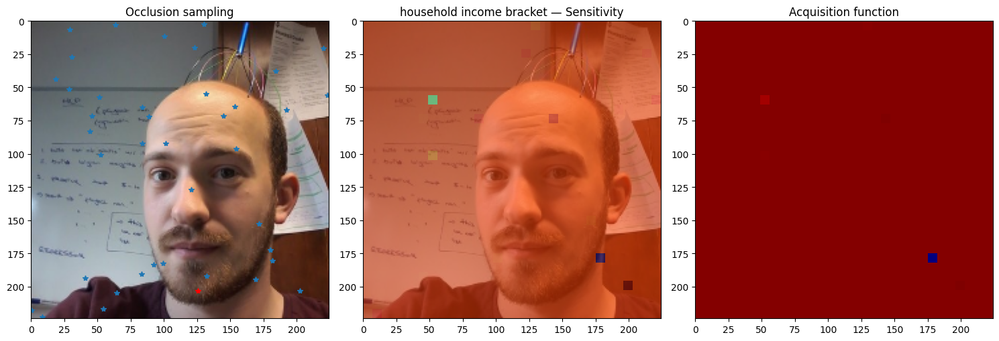


=== Plotting saliency for Image_Demo_partisan_loyalties_Speculation ===
[DEBUG] y_train stats: mean=1.0000, std=3.0000, min=0.0000, max=10.0000
[DEBUG] X_train stats: shape=(40, 4), x0_range=(0.149,15.973), y0_range=(0.025,16.000), w_range=(0.183,4.000), h_range=(0.152,4.382)
[DEBUG] mu mean=0.1000, std=0.0000, range=(0.0988,0.1000)
[DEBUG] sig mean=0.3000, std=0.0000, range=(0.3000,0.3000)


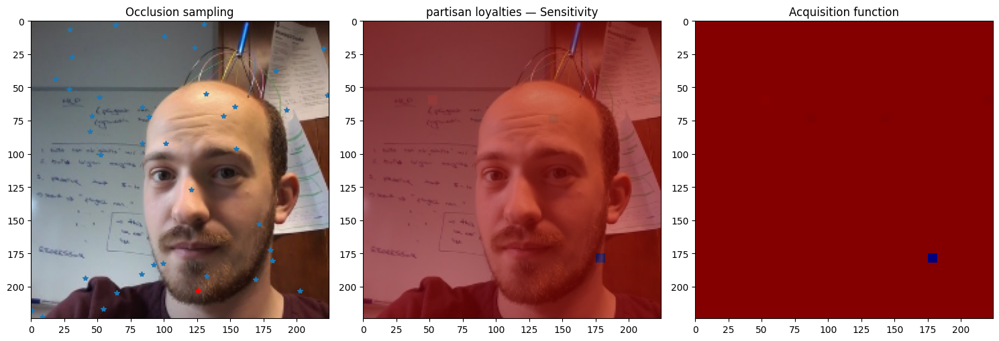

In [13]:
# ============================================================
# 9. Visualize saliency and acquisition per demographic feature (fixed + debug)
# ============================================================

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
import matplotlib.pyplot as plt
from IPython import display
import numpy as np

h_img, w_img = img.shape[:2]
scale_x = w_img / 32.0
scale_y = h_img / 32.0

for key, fm_values in fm_dict.items():
    if len(fm_values) < 2:
        continue

    print(f"\n=== Plotting saliency for {key} ===")
    n = min(len(Xm), len(fm_values))
    X_train = np.array(Xm[:n]) / np.array([2, 2, 2, 2])  # expanded normalization
    y_train = np.array(fm_values[:n])

    print(f"[DEBUG] y_train stats: mean={y_train.mean():.4f}, std={y_train.std():.4f}, "
          f"min={y_train.min():.4f}, max={y_train.max():.4f}")
    print(f"[DEBUG] X_train stats: shape={X_train.shape}, "
          f"x0_range=({X_train[:,0].min():.3f},{X_train[:,0].max():.3f}), "
          f"y0_range=({X_train[:,1].min():.3f},{X_train[:,1].max():.3f}), "
          f"w_range=({X_train[:,2].min():.3f},{X_train[:,2].max():.3f}), "
          f"h_range=({X_train[:,3].min():.3f},{X_train[:,3].max():.3f})")

    # Normalize target to [0,1]
    y_min, y_max = y_train.min(), y_train.max()
    if y_max != y_min:
        y_train = (y_train - y_min) / (y_max - y_min)
    else:
        y_train = np.zeros_like(y_train)

    kernel = Matern(length_scale_bounds=(1e-6, 1e4), nu=1.5)
    gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-2, normalize_y=True)
    gp.fit(X_train, y_train)

    X_norm = X / np.array([2, 2, 2, 2])
    mu, sig = gp.predict(X_norm, return_std=True)

    print(f"[DEBUG] mu mean={mu.mean():.4f}, std={mu.std():.4f}, range=({mu.min():.4f},{mu.max():.4f})")
    print(f"[DEBUG] sig mean={sig.mean():.4f}, std={sig.std():.4f}, range=({sig.min():.4f},{sig.max():.4f})")

    ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
    sxy = np.sum(sig.reshape(32, 32, -1), -1)

    # Plot
    x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
    y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
    x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
    y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img, extent=[0, w_img, h_img, 0])
    ax[0].plot(x_plot, y_plot, '*')
    ax[0].plot(x_last, y_last, 'r*')
    ax[0].set_xlim(0, w_img); ax[0].set_ylim(h_img, 0)
    ax[0].set_title("Occlusion sampling")

    ax[1].imshow(img, extent=[0, w_img, h_img, 0])
    ax[1].imshow(ov.T, alpha=0.5, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[1].set_xlim(0, w_img); ax[1].set_ylim(h_img, 0)
    ax[1].set_title(f"{key.replace('Image_Demo_', '').replace('_Speculation', '').replace('_', ' ')} — Sensitivity")

    ax[2].imshow(5 * sxy.T + ov.T, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[2].set_xlim(0, w_img); ax[2].set_ylim(h_img, 0)
    ax[2].set_title("Acquisition function")

    plt.tight_layout()
    display.display(fig)
    plt.close(fig)
